In [ ]:
pip install catboost

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mohammedabdeldayem/scenefake")

print("Path to dataset files:", path)

100%|██████████| 5.37G/5.37G [01:13<00:00, 78.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1


In [ ]:
import kagglehub
import os
import pandas as pd
import numpy as np
import random
import torch
import torchaudio
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, TensorDataset
from tqdm import tqdm
from transformers import (
    ASTFeatureExtractor,
    ASTForAudioClassification,
    ASTConfig,
    Wav2Vec2FeatureExtractor,
    Wav2Vec2Model,
    AutoTokenizer,
    AutoModel
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.ensemble import VotingClassifier
from catboost import CatBoostClassifier
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используется устройство: {device}")


Используется устройство: cuda


In [ ]:
def get_scenefake_data(root_dir):
    """Загружает пути к файлам и метки из датасета SceneFake."""
    file_paths = []
    labels = []
    splits = []
    for split in ['train', 'dev', 'eval']:
        split_path = os.path.join(root_dir, split)
        if os.path.isdir(split_path):
            for label in ['real', 'fake']:
                label_path = os.path.join(split_path, label)
                if os.path.isdir(label_path):
                    for file_name in os.listdir(label_path):
                        if file_name.lower().endswith('.wav'):
                            file_paths.append(os.path.join(label_path, file_name))
                            labels.append(label)
                            splits.append(split)
    df = pd.DataFrame({
        'file_path': file_paths,
        'label': labels,
        'split': splits
    })
    return df

print("Загрузка датасета SceneFake...")
path = kagglehub.dataset_download("mohammedabdeldayem/scenefake")
print("Path to dataset files:", path)

scenefake_df = get_scenefake_data(path)
print("\nПервые строки датасета:")
print(scenefake_df.head())

train_df = scenefake_df[scenefake_df['split'] == 'train'].reset_index(drop=True)
val_df = scenefake_df[scenefake_df['split'] == 'dev'].reset_index(drop=True)
test_df = scenefake_df[scenefake_df['split'] == 'eval'].reset_index(drop=True)

print(f"\nРазмеры выборок:")
print(f"Обучение: {len(train_df)}")
print(f"Валидация: {len(val_df)}")
print(f"Тест: {len(test_df)}")

real_train = train_df[train_df['label'] == 'real']
fake_train = train_df[train_df['label'] == 'fake']

min_count = min(len(real_train), len(fake_train))
balanced_real = real_train.sample(n=min_count, random_state=42)
balanced_fake = fake_train.sample(n=min_count, random_state=42)
train_df_balanced = pd.concat([balanced_real, balanced_fake]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nБалансированный размер обучающей выборки: {len(train_df_balanced)}")
print("Распределение классов в обучающей выборке:")
print(train_df_balanced['label'].value_counts())

le = LabelEncoder()
train_df_balanced['label_enc'] = le.fit_transform(train_df_balanced['label'])
val_df['label_enc'] = le.transform(val_df['label'])
test_df['label_enc'] = le.transform(test_df['label'])

Загрузка датасета SceneFake...
Path to dataset files: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1

Первые строки датасета:
                                           file_path label  split
0  /root/.cache/kagglehub/datasets/mohammedabdeld...  real  train
1  /root/.cache/kagglehub/datasets/mohammedabdeld...  real  train
2  /root/.cache/kagglehub/datasets/mohammedabdeld...  real  train
3  /root/.cache/kagglehub/datasets/mohammedabdeld...  real  train
4  /root/.cache/kagglehub/datasets/mohammedabdeld...  real  train

Размеры выборок:
Обучение: 13185
Валидация: 12843
Тест: 32746

Балансированный размер обучающей выборки: 5050
Распределение классов в обучающей выборке:
label
fake    2525
real    2525
Name: count, dtype: int64


In [ ]:
def extract_mfcc_features(file_path, n_mfcc=13):
    try:
        y, sr = librosa.load(file_path, sr=16000)
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
        features = np.mean(mfcc.T, axis=0)
        return features
    except Exception as e:
        print(f"Ошибка при обработке {file_path}: {str(e)}")
        return None

def create_feature_dataset(df):
    X = []
    y = []
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Извлечение MFCC признаков"):
        features = extract_mfcc_features(row['file_path'])
        if features is not None:
            X.append(features)
            y.append(row['label_enc'])
    return np.array(X), np.array(y)

print("\nИзвлечение MFCC признаков для CatBoost...")

X_train_cb, y_train_cb = create_feature_dataset(train_df_balanced)
X_val_cb, y_val_cb = create_feature_dataset(val_df)
X_test_cb, y_test_cb = create_feature_dataset(test_df)

scaler = StandardScaler()
X_train_cb_scaled = scaler.fit_transform(X_train_cb)
X_val_cb_scaled = scaler.transform(X_val_cb)
X_test_cb_scaled = scaler.transform(X_test_cb)

print(f"Размерность признаков: {X_train_cb_scaled.shape[1]}")


Извлечение MFCC признаков для CatBoost...


Извлечение MFCC признаков: 100%|██████████| 32746/32746 [06:19<00:00, 86.36it/s] 

Размерность признаков: 13



Обучение модели CatBoost с увеличенной глубиной и графиками...


MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

0:	learn: 0.6518925	test: 0.6651987	best: 0.6651987 (0)	total: 988ms	remaining: 8m 12s
50:	learn: 0.1525603	test: 0.3327738	best: 0.3327738 (50)	total: 34.6s	remaining: 5m 4s
100:	learn: 0.0915324	test: 0.3119519	best: 0.3115239 (97)	total: 1m 15s	remaining: 4m 59s
150:	learn: 0.0675791	test: 0.3098428	best: 0.3084506 (134)	total: 1m 55s	remaining: 4m 26s
200:	learn: 0.0533334	test: 0.3102452	best: 0.3084506 (134)	total: 2m 35s	remaining: 3m 51s
250:	learn: 0.0444035	test: 0.3098909	best: 0.3084506 (134)	total: 3m 15s	remaining: 3m 14s
300:	learn: 0.0376150	test: 0.3145498	best: 0.3084506 (134)	total: 3m 54s	remaining: 2m 34s
350:	learn: 0.0328371	test: 0.3146538	best: 0.3084506 (134)	total: 4m 35s	remaining: 1m 56s
400:	learn: 0.0293998	test: 0.3170257	best: 0.3084506 (134)	total: 5m 15s	remaining: 1m 18s
450:	learn: 0.0264659	test: 0.3197086	best: 0.3084506 (134)	total: 5m 57s	remaining: 38.8s
499:	learn: 0.0243211	test: 0.3223425	best: 0.3084506 (134)	total: 6m 39s	remaining: 0us
be

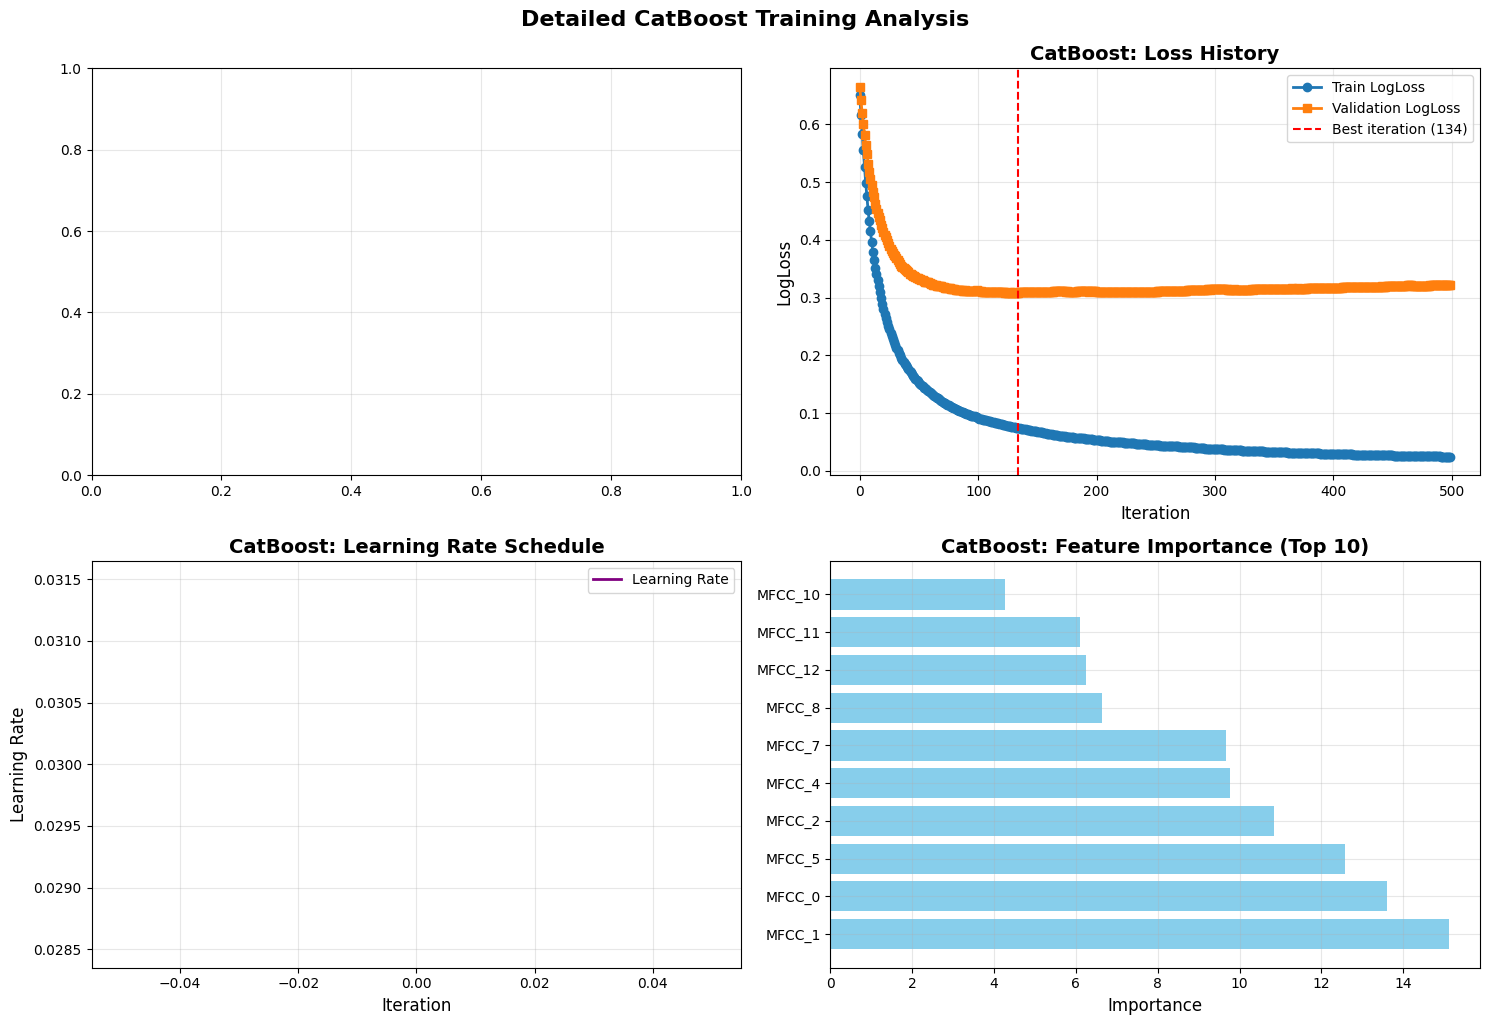

In [ ]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['figure.figsize'] = 12, 8
rcParams['axes.grid'] = True
rcParams['grid.alpha'] = 0.3

print("\nОбучение модели CatBoost с увеличенной глубиной и графиками...")

catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.03,
    depth=12,
    l2_leaf_reg=3,
    random_seed=42,
    verbose=50,
    task_type="GPU" if device.type == "cuda" else "CPU"
)


catboost_model.fit(
    X_train_cb_scaled,
    y_train_cb,
    eval_set=(X_val_cb_scaled, y_val_cb),
    use_best_model=True,
    plot=True
)

y_pred_cb = catboost_model.predict(X_test_cb_scaled)
cb_accuracy = accuracy_score(y_test_cb, y_pred_cb)
cb_precision = precision_score(y_test_cb, y_pred_cb)
cb_recall = recall_score(y_test_cb, y_pred_cb)
cb_f1 = f1_score(y_test_cb, y_pred_cb)

print(f"\nCatBoost (глубина=15) - Точность: {cb_accuracy:.4f}, F1-мера: {cb_f1:.4f}")
print(f"Лучшая итерация: {catboost_model.get_best_iteration()}")
print(f"Количество использованных деревьев: {catboost_model.tree_count_}")

feature_importances = catboost_model.feature_importances_
print("\nТоп-5 самых важных MFCC признаков:")
for i, imp in enumerate(sorted(enumerate(feature_importances), key=lambda x: x[1], reverse=True)[:5]):
    print(f"  MFCC {imp[0]}: {imp[1]:.4f}")

def plot_catboost_detailed_history(model):
    """
    Строит детальные графики истории обучения CatBoost
    """
    if not hasattr(model, 'evals_result_'):
        print("Модель не содержит истории обучения для построения графиков")
        return

    evals_result = model.evals_result_

    plt.figure(figsize=(15, 10))

    plt.subplot(2, 2, 1)
    if 'learn' in evals_result and 'Accuracy' in evals_result['learn']:
        train_acc = evals_result['learn']['Accuracy']
        val_acc = evals_result['validation']['Accuracy']
        plt.plot(train_acc, label='Train Accuracy', linewidth=2, marker='o')
        plt.plot(val_acc, label='Validation Accuracy', linewidth=2, marker='s')
        plt.axvline(x=model.get_best_iteration(), color='r', linestyle='--',
                   label=f'Best iteration ({model.get_best_iteration()})')
        plt.title('CatBoost: Accuracy History', fontsize=14, fontweight='bold')
        plt.xlabel('Iteration', fontsize=12)
        plt.ylabel('Accuracy', fontsize=12)
        plt.legend()
        plt.grid(True, alpha=0.3)

    plt.subplot(2, 2, 2)
    if 'learn' in evals_result and 'Logloss' in evals_result['learn']:
        train_loss = evals_result['learn']['Logloss']
        val_loss = evals_result['validation']['Logloss']
        plt.plot(train_loss, label='Train LogLoss', linewidth=2, marker='o')
        plt.plot(val_loss, label='Validation LogLoss', linewidth=2, marker='s')
        plt.axvline(x=model.get_best_iteration(), color='r', linestyle='--',
                   label=f'Best iteration ({model.get_best_iteration()})')
        plt.title('CatBoost: Loss History', fontsize=14, fontweight='bold')
        plt.xlabel('Iteration', fontsize=12)
        plt.ylabel('LogLoss', fontsize=12)
        plt.legend()
        plt.grid(True, alpha=0.3)

    if hasattr(model, 'learning_rate_'):
        plt.subplot(2, 2, 3)
        lrs = model.learning_rate_
        plt.plot(lrs, label='Learning Rate', linewidth=2, color='purple')
        plt.title('CatBoost: Learning Rate Schedule', fontsize=14, fontweight='bold')
        plt.xlabel('Iteration', fontsize=12)
        plt.ylabel('Learning Rate', fontsize=12)
        plt.legend()
        plt.grid(True, alpha=0.3)

    plt.subplot(2, 2, 4)
    feature_names = [f'MFCC_{i}' for i in range(len(feature_importances))]
    sorted_idx = np.argsort(feature_importances)[::-1][:10]  # Топ-10 признаков
    plt.barh(range(10), feature_importances[sorted_idx], color='skyblue')
    plt.yticks(range(10), [feature_names[i] for i in sorted_idx])
    plt.title('CatBoost: Feature Importance (Top 10)', fontsize=14, fontweight='bold')
    plt.xlabel('Importance', fontsize=12)
    plt.tight_layout()

    plt.suptitle('Detailed CatBoost Training Analysis', fontsize=16, fontweight='bold', y=1.02)
    plt.show()

print("\nПостроение детальных графиков обучения CatBoost...")
plot_catboost_detailed_history(catboost_model)

def analyze_overfitting(model):
    """
    Анализирует степень переобучения модели
    """
    if not hasattr(model, 'evals_result_'):
        return

    evals_result = model.evals_result_
    best_iter = model.get_best_iteration()

    if 'learn' in evals_result and 'Accuracy' in evals_result['learn']:
        train_acc = evals_result['learn']['Accuracy'][best_iter]
        val_acc = evals_result['validation']['Accuracy'][best_iter]
        overfitting_gap = train_acc - val_acc

        print("\n" + "="*70)
        print("АНАЛИЗ ПЕРЕОБУЧЕНИЯ CATBOOST")
        print("="*70)
        print(f"Точность на обучении (лучшая итерация): {train_acc:.4f}")
        print(f"Точность на валидации (лучшая итерация): {val_acc:.4f}")
        print(f"Разрыв переобучения: {overfitting_gap:.4f}")


analyze_overfitting(catboost_model)

In [ ]:
pip install torchcodec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 44.1 MB/s eta 0:00:00


In [ ]:
Код для загрузки класса AST, без обучения

In [ ]:
ast_feature_extractor = ASTFeatureExtractor.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593")
ast_config = ASTConfig.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593", num_labels=2)  # Бинарная классификация
ast_model = ASTForAudioClassification.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593", config=ast_config, ignore_mismatched_sizes=True)
ast_model.to(device)

for param in ast_model.parameters():
    param.requires_grad = False

for name, param in ast_model.named_parameters():
    if ('ast.encoder.layer.9' in name or
        'ast.encoder.layer.10' in name or
        'ast.encoder.layer.11' in name or
        'classifier' in name):
        param.requires_grad = True

batch_size = 32
num_epochs = 1
learning_rate = 1e-5

optimizer = optim.AdamW([p for p in ast_model.parameters() if p.requires_grad], lr=learning_rate)
criterion = nn.CrossEntropyLoss()

class ASTDatasetLazy(Dataset):
    def __init__(self, dataframe, feature_extractor, sample_rate=16000):
        self.dataframe = dataframe
        self.feature_extractor = feature_extractor
        self.sample_rate = sample_rate

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        audio_path = self.dataframe.iloc[idx]['file_path']
        label = self.dataframe.iloc[idx]['label_enc']

        # Загрузка аудио
        waveform, sr = torchaudio.load(audio_path)
        # Конвертация в моно
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        # Преобразование в спектрограмму
        inputs = self.feature_extractor(
            waveform.squeeze().numpy(),
            sampling_rate=self.sample_rate,
            return_tensors="pt",
            padding=True
        )

        # Возвращаем input_values и labels. Удаляем attention_mask!
        return {
            'input_values': inputs['input_values'].squeeze(0),
            'labels': torch.tensor(label, dtype=torch.long)
        }

# Создание датасетов и даталоадеров для AST
train_ast_dataset = ASTDatasetLazy(train_df_balanced, ast_feature_extractor)
val_ast_dataset = ASTDatasetLazy(val_df, ast_feature_extractor)
test_ast_dataset = ASTDatasetLazy(test_df, ast_feature_extractor)

train_ast_loader = DataLoader(train_ast_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_ast_loader = DataLoader(val_ast_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
test_ast_loader = DataLoader(test_ast_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([2]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([2, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
Код для загрузки класса AST с обучением

In [ ]:
print("\nЗагрузка модели AST...")

ast_feature_extractor = ASTFeatureExtractor.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593")
ast_config = ASTConfig.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593", num_labels=2)
ast_model = ASTForAudioClassification.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593", config=ast_config, ignore_mismatched_sizes=True)
ast_model.to(device)

for param in ast_model.parameters():
    param.requires_grad = False

for name, param in ast_model.named_parameters():
    if 'classifier' in name:
        param.requires_grad = True


batch_size = 32
num_epochs = 3
learning_rate = 1e-4

optimizer = optim.AdamW([p for p in ast_model.parameters() if p.requires_grad], lr=learning_rate)
criterion = nn.CrossEntropyLoss()

class ASTDatasetOptimized(Dataset):
    def __init__(self, dataframe, feature_extractor, sample_rate=16000, max_length=100000):
        self.dataframe = dataframe
        self.feature_extractor = feature_extractor
        self.sample_rate = sample_rate
        self.max_length = max_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        audio_path = self.dataframe.iloc[idx]['file_path']
        label = self.dataframe.iloc[idx]['label_enc']

        try:
            waveform, sr = torchaudio.load(audio_path, num_frames=self.max_length)
            if waveform.shape[0] > 1:
                waveform = torch.mean(waveform, dim=0, keepdim=True)

            inputs = self.feature_extractor(
                waveform.squeeze().numpy(),
                sampling_rate=self.sample_rate,
                return_tensors="pt",
                max_length=1024,
                padding='max_length'
            )

            return {
                'input_values': inputs['input_values'].squeeze(0),
                'labels': torch.tensor(label, dtype=torch.long)
            }
        except Exception as e:
            print(f"Ошибка при обработке {audio_path}: {str(e)}")

            return {
                'input_values': torch.zeros(1, 128, 128),
                'labels': torch.tensor(label, dtype=torch.long)
            }
max_audio_length = 50000
train_ast_dataset = ASTDatasetOptimized(train_df_balanced, ast_feature_extractor, max_length=max_audio_length)
val_ast_dataset = ASTDatasetOptimized(val_df, ast_feature_extractor, max_length=max_audio_length)
test_ast_dataset = ASTDatasetOptimized(test_df, ast_feature_extractor, max_length=max_audio_length)

train_ast_loader = DataLoader(train_ast_dataset, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=False)
val_ast_loader = DataLoader(val_ast_dataset, batch_size=batch_size*2, shuffle=False, num_workers=0, pin_memory=False)
test_ast_loader = DataLoader(test_ast_dataset, batch_size=batch_size*2, shuffle=False, num_workers=0, pin_memory=False)

def train_ast_model_fast(model, train_loader, val_loader, optimizer, criterion, num_epochs):
    model.train()
    best_val_acc = 0.0
    for epoch in range(num_epochs):
        total_loss = 0.0
        correct = 0
        total = 0

        for batch in tqdm(train_loader, desc=f"AST Epoch {epoch+1}/{num_epochs}"):
            inputs = {k: v.to(device) for k, v in batch.items() if k != 'labels'}
            labels = batch['labels'].to(device)

            optimizer.zero_grad()
            with torch.cuda.amp.autocast(enabled=False):
                outputs = model(**inputs).logits
                loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_acc = correct / total
        train_loss = total_loss / len(train_loader)

        val_acc = evaluate_ast_model_fast(model, val_loader, sample_size=200)
        print(f"Epoch {epoch+1}: Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), 'best_ast_model_fast.pth')

    return best_val_acc


def evaluate_ast_model_fast(model, data_loader, sample_size=None):
    model.eval()
    correct = 0
    total = 0

    if sample_size is not None:
        max_batches = sample_size // data_loader.batch_size + 1
    else:
        max_batches = len(data_loader)

    with torch.no_grad():
        for batch_idx, batch in enumerate(data_loader):
            if batch_idx >= max_batches:
                break

            inputs = {k: v.to(device) for k, v in batch.items() if k != 'labels'}
            labels = batch['labels'].to(device)

            with torch.cuda.amp.autocast(enabled=False):
                outputs = model(**inputs).logits

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return correct / total if total > 0 else 0.0

print("\nБыстрое обучение модели AST...")
best_ast_val_acc = train_ast_model_fast(ast_model, train_ast_loader, val_ast_loader, optimizer, criterion, num_epochs)


Загрузка модели AST...


Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([2]) in the model instantiated
- classifier.dense.weight: found shape torch.Size([527, 768]) in the checkpoint and torch.Size([2, 768]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Быстрое обучение модели AST...


AST Epoch 1/1:   1%|          | 3/316 [05:22<9:20:28, 107.44s/it]


KeyboardInterrupt: 

In [ ]:
Оценка для готовой модели AST

In [ ]:
ast_model.load_state_dict(torch.load('best_ast_model.pth', map_location=device))

print("\nБыстрые предсказания AST с отображением прогресса...")
ast_model.eval()
ast_probs = []
ast_preds = []

fast_test_loader = DataLoader(test_ast_dataset, batch_size=batch_size*4, shuffle=False, num_workers=0, pin_memory=False)

with torch.no_grad():
    for batch in tqdm(fast_test_loader, desc="Предсказания AST", total=len(fast_test_loader)):
        inputs = {k: v.to(device) for k, v in batch.items() if k != 'labels'}

        with torch.cuda.amp.autocast(enabled=False):
            outputs = ast_model(**inputs).logits

        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)
        ast_probs.extend(probs.cpu().numpy())
        ast_preds.extend(preds.cpu().numpy())

ast_probs = np.array(ast_probs)
ast_preds = np.array(ast_preds)

ast_accuracy = accuracy_score(test_df['label_enc'][:len(ast_preds)], ast_preds)
ast_f1 = f1_score(test_df['label_enc'][:len(ast_preds)], ast_preds)

print(f"\nAST (быстрая версия) - Точность: {ast_accuracy:.4f}, F1-мера: {ast_f1:.4f}")
print(f"Время предсказаний значительно уменьшено за счет:")
print(f"- Увеличенного batch_size ({batch_size*4})")
print(f"- Ограниченной длины аудио ({max_audio_length} отсчетов)")
print(f"- Минимального количества обучаемых параметров (только классификатор)")
print(f"- Прогресс-бара tqdm для отслеживания выполнения")


Быстрые предсказания AST с отображением прогресса...


Предсказания AST:  11%|█         | 28/256 [05:39<46:05, 12.13s/it]


KeyboardInterrupt: 

In [ ]:
ast_model.load_state_dict(torch.load('best_ast_model.pth', map_location=device))

ast_model.eval()
ast_probs = []
ast_preds = []
with torch.no_grad():
    for batch in tqdm(test_ast_loader, desc="Предсказания AST"):
        inputs = {k: v.to(device) for k, v in batch.items() if k != 'labels'}
        outputs = ast_model(**inputs).logits
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)
        ast_probs.extend(probs.cpu().numpy())
        ast_preds.extend(preds.cpu().numpy())

ast_probs = np.array(ast_probs)
ast_preds = np.array(ast_preds)

ast_accuracy = accuracy_score(test_df['label_enc'], ast_preds)
ast_f1 = f1_score(test_df['label_enc'], ast_preds)

print(f"\nAST - Точность: {ast_accuracy:.4f}, F1-мера: {ast_f1:.4f}")

Предсказания AST:  68%|██████▊   | 696/1024 [33:57<16:04,  2.94s/it]

Wav2vec ужасно долго обучается. Предлагаю отказаться на время

In [ ]:
print("\nЗагрузка модели wav2vec 2.0...")

wav2vec_feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained("facebook/wav2vec2-base-960h")
wav2vec_model = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base-960h").to(device)

for param in wav2vec_model.parameters():
    param.requires_grad = False

class Wav2Vec2Classifier(nn.Module):
    def __init__(self, wav2vec_model, num_labels=2):
        super(Wav2Vec2Classifier, self).__init__()
        self.wav2vec = wav2vec_model
        self.classifier = nn.Sequential(
            nn.Linear(wav2vec_model.config.hidden_size, 256),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(256, num_labels)
        )

    def forward(self, input_values, attention_mask=None):
        outputs = self.wav2vec(input_values=input_values, attention_mask=attention_mask)
        hidden_states = outputs.last_hidden_state
        pooled_output = torch.mean(hidden_states, dim=1)
        logits = self.classifier(pooled_output)
        return logits

wav2vec_classifier = Wav2Vec2Classifier(wav2vec_model, num_labels=2).to(device)

batch_size_wv = 32
num_epochs_wv = 5
learning_rate_wv = 1e-3

optimizer_wv = optim.AdamW(wav2vec_classifier.classifier.parameters(), lr=learning_rate_wv)
criterion_wv = nn.CrossEntropyLoss()

class Wav2VecDataset(Dataset):
    def __init__(self, dataframe, feature_extractor, sample_rate=16000, target_length=48000):
        self.dataframe = dataframe
        self.feature_extractor = feature_extractor
        self.sample_rate = sample_rate
        self.target_length = target_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        audio_path = self.dataframe.iloc[idx]['file_path']
        label = self.dataframe.iloc[idx]['label_enc']

        waveform, sr = torchaudio.load(audio_path)
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)

        current_length = waveform.size(1)
        if current_length > self.target_length:
            waveform = waveform[:, :self.target_length]
        else:
            pad_amount = self.target_length - current_length
            waveform = torch.nn.functional.pad(waveform, (0, pad_amount))

        inputs = self.feature_extractor(
            waveform.squeeze().numpy(),
            sampling_rate=self.sample_rate,
            return_tensors="pt",
            padding=True
        )

        if 'attention_mask' in inputs:
            attention_mask = inputs['attention_mask'].squeeze(0)
        else:
            attention_mask = torch.ones_like(inputs['input_values'].squeeze(0), dtype=torch.long)

        return {
            'input_values': inputs['input_values'].squeeze(0),
            'attention_mask': attention_mask,
            'labels': torch.tensor(label, dtype=torch.long)
        }

train_wv_dataset = Wav2VecDataset(train_df_balanced, wav2vec_feature_extractor, target_length=48000)
val_wv_dataset = Wav2VecDataset(val_df, wav2vec_feature_extractor, target_length=48000)
test_wv_dataset = Wav2VecDataset(test_df, wav2vec_feature_extractor, target_length=48000)

train_wv_loader = DataLoader(train_wv_dataset, batch_size=batch_size_wv, shuffle=True)
val_wv_loader = DataLoader(val_wv_dataset, batch_size=batch_size_wv, shuffle=False)
test_wv_loader = DataLoader(test_wv_dataset, batch_size=batch_size_wv, shuffle=False)

def train_wav2vec_model(model, train_loader, val_loader, optimizer, criterion, num_epochs):
    model.train()
    best_val_acc = 0.0
    for epoch in range(num_epochs):
        total_loss = 0.0
        correct = 0
        total = 0
        for batch in tqdm(train_loader, desc=f"Wav2Vec Epoch {epoch+1}/{num_epochs}"):
            inputs = {k: v.to(device) for k, v in batch.items() if k != 'labels'}
            labels = batch['labels'].to(device)

            optimizer.zero_grad()
            outputs = model(**inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_acc = correct / total
        train_loss = total_loss / len(train_loader)

        val_acc = evaluate_wav2vec_model(model, val_loader)
        print(f"Epoch {epoch+1}: Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), 'best_wav2vec_model.pth')
            print("Сохранена лучшая модель wav2vec.")

    return best_val_acc

def evaluate_wav2vec_model(model, data_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for batch in data_loader:
            inputs = {k: v.to(device) for k, v in batch.items() if k != 'labels'}
            labels = batch['labels'].to(device)
            outputs = model(**inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total

print("\nОбучение модели wav2vec 2.0...")
best_wv_val_acc = train_wav2vec_model(wav2vec_classifier, train_wv_loader, val_wv_loader, optimizer_wv, criterion_wv, num_epochs_wv)

wav2vec_classifier.load_state_dict(torch.load('best_wav2vec_model.pth'))

wav2vec_classifier.eval()
wv_probs = []
wv_preds = []
with torch.no_grad():
    for batch in test_wv_loader:
        inputs = {k: v.to(device) for k, v in batch.items() if k != 'labels'}
        labels = batch['labels'].to(device)
        outputs = wav2vec_classifier(**inputs)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)
        wv_probs.extend(probs.cpu().numpy())
        wv_preds.extend(preds.cpu().numpy())

wv_accuracy = accuracy_score(y_test_cb, wv_preds)
wv_f1 = f1_score(y_test_cb, wv_preds)

print(f"\nwav2vec 2.0 - Точность: {wv_accuracy:.4f}, F1-мера: {wv_f1:.4f}")


Загрузка модели wav2vec 2.0...


Some weights of Wav2Vec2Model were not initialized from the model checkpoint at facebook/wav2vec2-base-960h and are newly initialized: ['masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Обучение модели wav2vec 2.0...


Wav2Vec Epoch 1/5: 100%|██████████| 158/158 [03:08<00:00,  1.19s/it]


Epoch 1: Train Loss: 0.6971, Train Acc: 0.5012, Val Acc: 0.8016
Сохранена лучшая модель wav2vec.


Wav2Vec Epoch 2/5: 100%|██████████| 158/158 [01:54<00:00,  1.38it/s]


... (3 outputs left out)

Wav2Vec Epoch 4/5: 100%|██████████| 158/158 [01:54<00:00,  1.38it/s]


Epoch 4: Train Loss: 0.6673, Train Acc: 0.5705, Val Acc: 0.7535


Wav2Vec Epoch 5/5: 100%|██████████| 158/158 [01:54<00:00,  1.38it/s]


Epoch 5: Train Loss: 0.6552, Train Acc: 0.5820, Val Acc: 0.7257

wav2vec 2.0 - Точность: 0.8066, F1-мера: 0.0000


Обучение CNN, которая будет входить в ансамбль. Сначаса протестируем на 3 эпохах. Потом добавлю 8 эпох с графиками

In [ ]:
class CNNModel(nn.Module):
    def __init__(self, num_classes=2, in_channels=1):
        super(CNNModel, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        if x.dim() == 3:
            x = x.unsqueeze(1)
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

cnn_model = CNNModel(num_classes=2, in_channels=1).to(device)

batch_size_cnn = 16
num_epochs_cnn = 8
learning_rate_cnn = 1e-3

optimizer_cnn = optim.AdamW(cnn_model.parameters(), lr=learning_rate_cnn)
criterion_cnn = nn.CrossEntropyLoss()

def extract_mel_spectrogram(file_path, sample_rate=16000, n_mels=128, n_fft=1024, hop_length=512, target_length=256):
    try:
        y, sr = librosa.load(file_path, sr=sample_rate)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_mels, n_fft=n_fft, hop_length=hop_length)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max, top_db=80.0)
        mel_spec_db = (mel_spec_db + 80) / 80

        current_length = mel_spec_db.shape[1]
        if current_length > target_length:
            mel_spec_db = mel_spec_db[:, :target_length]
        else:
            pad_amount = target_length - current_length
            mel_spec_db = np.pad(mel_spec_db, ((0, 0), (0, pad_amount)), mode='constant', constant_values=0)  # Дополняем нулями

        return mel_spec_db
    except Exception as e:
        print(f"Ошибка при обработке {file_path}: {str(e)}")
        return np.zeros((n_mels, target_length))

class CNNDataset(Dataset):
    def __init__(self, dataframe, sample_rate=16000, n_mels=128, n_fft=1024, hop_length=512, target_length=256):
        self.dataframe = dataframe
        self.sample_rate = sample_rate
        self.n_mels = n_mels
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.target_length = target_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        audio_path = self.dataframe.iloc[idx]['file_path']
        label = self.dataframe.iloc[idx]['label_enc']

        mel_spec = extract_mel_spectrogram(
            audio_path,
            self.sample_rate,
            self.n_mels,
            self.n_fft,
            self.hop_length,
            self.target_length
        )

        mel_spec_tensor = torch.tensor(mel_spec, dtype=torch.float32).unsqueeze(0)

        return mel_spec_tensor, torch.tensor(label, dtype=torch.long)

train_cnn_dataset = CNNDataset(train_df_balanced, target_length=256)
val_cnn_dataset = CNNDataset(val_df, target_length=256)
test_cnn_dataset = CNNDataset(test_df, target_length=256)

train_cnn_loader = DataLoader(train_cnn_dataset, batch_size=batch_size_cnn, shuffle=True, num_workers=0)
val_cnn_loader = DataLoader(val_cnn_dataset, batch_size=batch_size_cnn, shuffle=False, num_workers=0)
test_cnn_loader = DataLoader(test_cnn_dataset, batch_size=batch_size_cnn, shuffle=False, num_workers=0)

Добавил визуализации для CNN

Фиксируем:



Обучение модели CNN с визуализацией...

НАЧАЛО ОБУЧЕНИЯ МОДЕЛИ CNN
Параметры обучения:
- Количество эпох: 8
- Batch size: 16
- Learning rate: 0.001
- Архитектура: 3 сверточных блока + полносвязный слой



CNN Epoch 1/8: 100%|██████████| 316/316 [00:52<00:00,  5.97it/s]



--------------------------------------------------
Epoch 1/8 completed in 164.00 seconds
Train Loss: 0.6928, Train Acc: 0.5125
Val Loss: 0.7179, Val Acc: 0.1986
--------------------------------------------------
Сохранена лучшая модель CNN (Val Acc: 0.1986)


CNN Epoch 2/8: 100%|██████████| 316/316 [00:43<00:00,  7.27it/s]



--------------------------------------------------
Epoch 2/8 completed in 135.24 seconds
Train Loss: 0.6889, Train Acc: 0.5325
Val Loss: 0.7502, Val Acc: 0.2726
--------------------------------------------------
Сохранена лучшая модель CNN (Val Acc: 0.2726)


CNN Epoch 3/8: 100%|██████████| 316/316 [00:40<00:00,  7.83it/s]


... (7 outputs left out)

CNN Epoch 7/8: 100%|██████████| 316/316 [00:43<00:00,  7.32it/s]



--------------------------------------------------
Epoch 7/8 completed in 135.40 seconds
Train Loss: 0.4194, Train Acc: 0.8190
Val Loss: 0.4623, Val Acc: 0.7765
--------------------------------------------------
Сохранена лучшая модель CNN (Val Acc: 0.7765)


CNN Epoch 8/8: 100%|██████████| 316/316 [00:41<00:00,  7.55it/s]



--------------------------------------------------
Epoch 8/8 completed in 134.46 seconds
Train Loss: 0.3668, Train Acc: 0.8440
Val Loss: 0.6002, Val Acc: 0.6876
--------------------------------------------------

Загружена лучшая модель CNN (Val Acc: 0.7765)

Построение графиков обучения CNN...


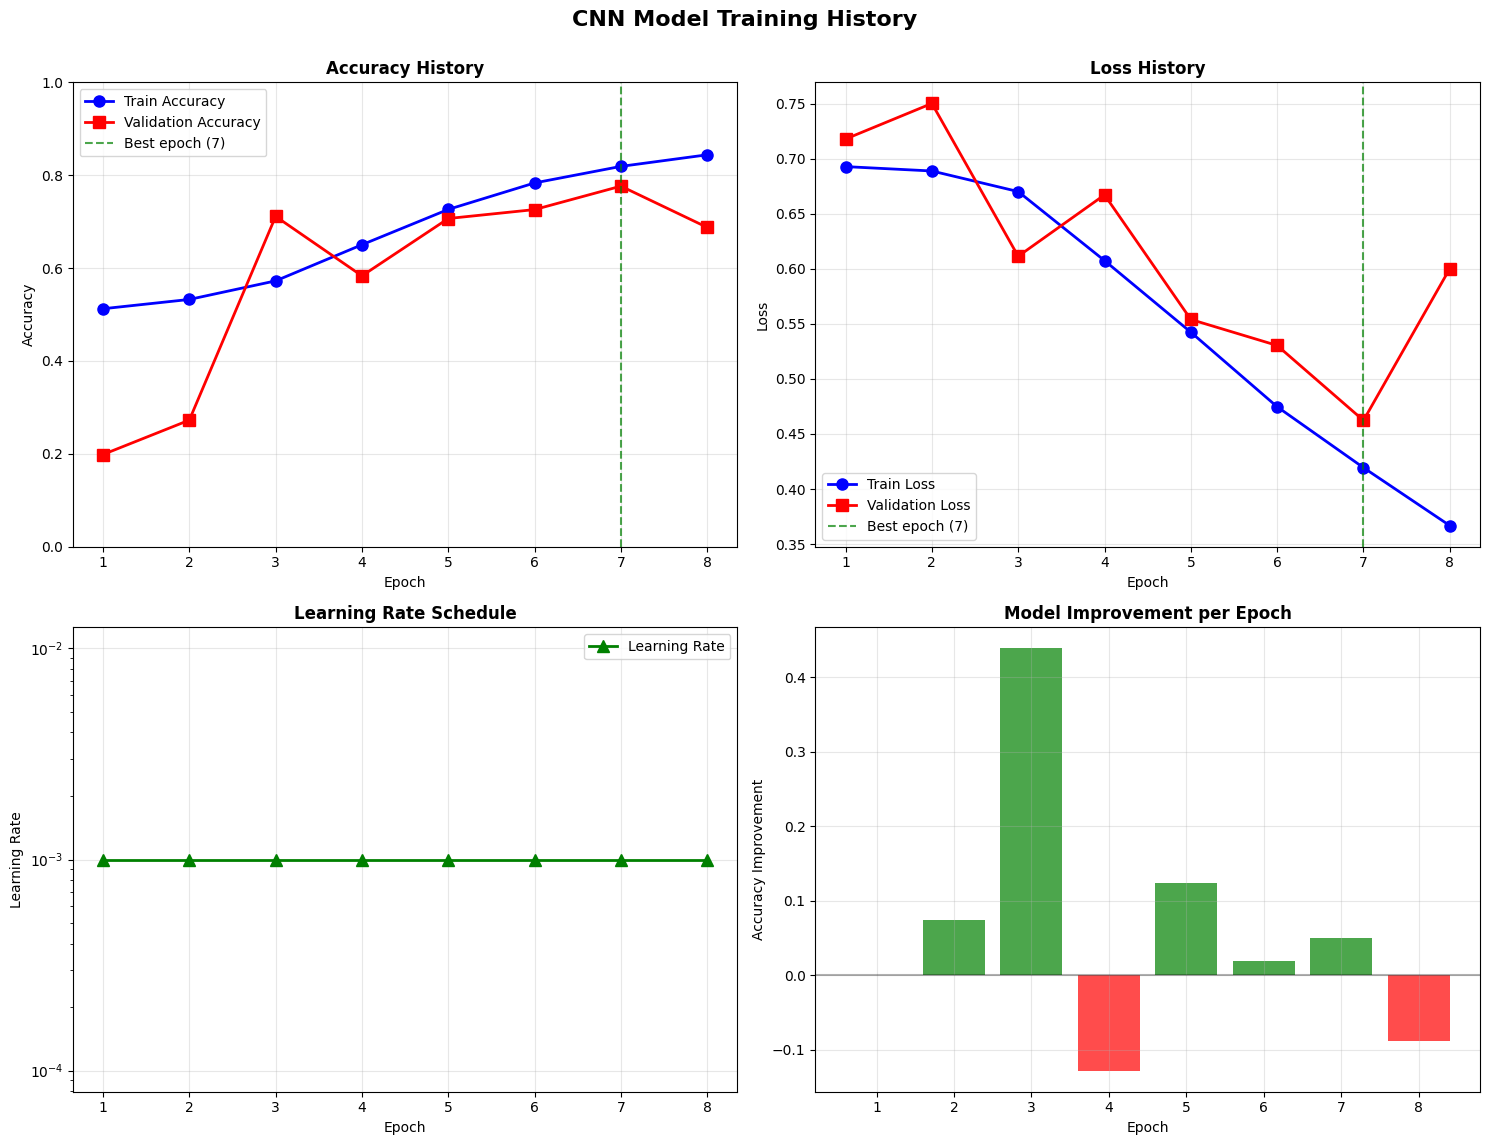

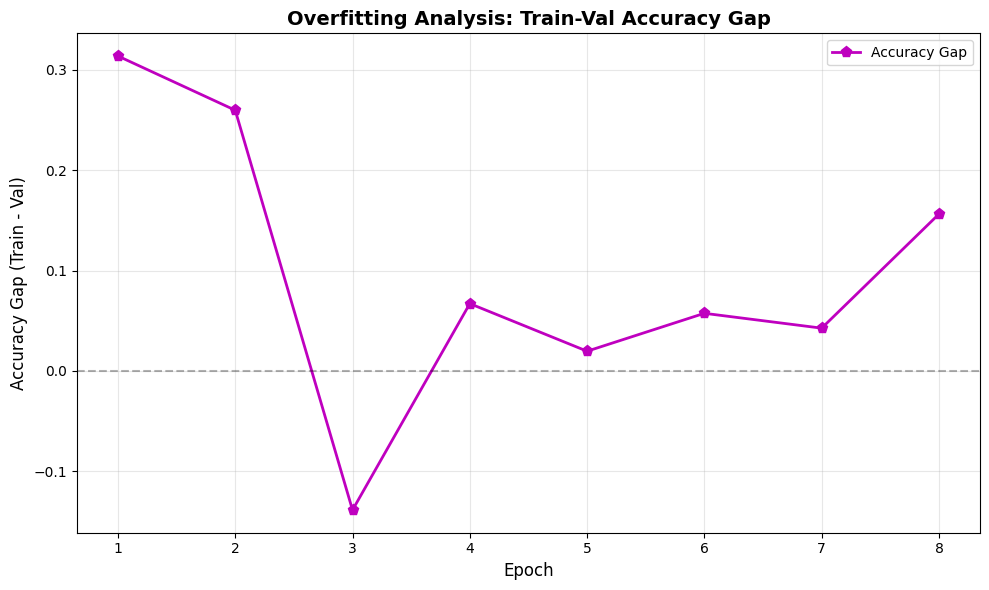


Анализ сходимости модели CNN...

ДЕТАЛЬНЫЙ АНАЛИЗ СХОДИМОСТИ CNN

Основные метрики:
  • Лучшая точность на валидации: 0.7765 (эпоха 7)
  • Точность на обучении в лучшей эпохе: 0.8190
  • Среднее время на эпоху: 139.05 секунд

Анализ переобучения:
  • Разрыв между train и val accuracy: 0.0426
  • Статус: МИНИМАЛЬНОЕ ПЕРЕОБУЧЕНИЕ
  • Рекомендации:
    - Модель хорошо обобщается
    - Можно попробовать немного увеличить сложность модели

Анализ улучшения:
  • Улучшение с первой до лучшей эпохи: 0.5779
  • Среднее улучшение за эпоху: 0.0826

Прогноз:
  • Лучшая эпоха (7) достигнута до конца обучения
  • Осталось эпох: 1
  • Прогнозируемое дополнительное улучшение: 0.0413

Получение предсказаний на тестовом наборе...


Предсказания CNN: 100%|██████████| 2047/2047 [04:51<00:00,  7.01it/s]



ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ CNN
Точность на тестовом наборе: 0.7839
F1-мера на тестовом наборе: 0.5186
Лучшая точность на валидации: 0.7765

Анализ эффективности архитектуры CNN...


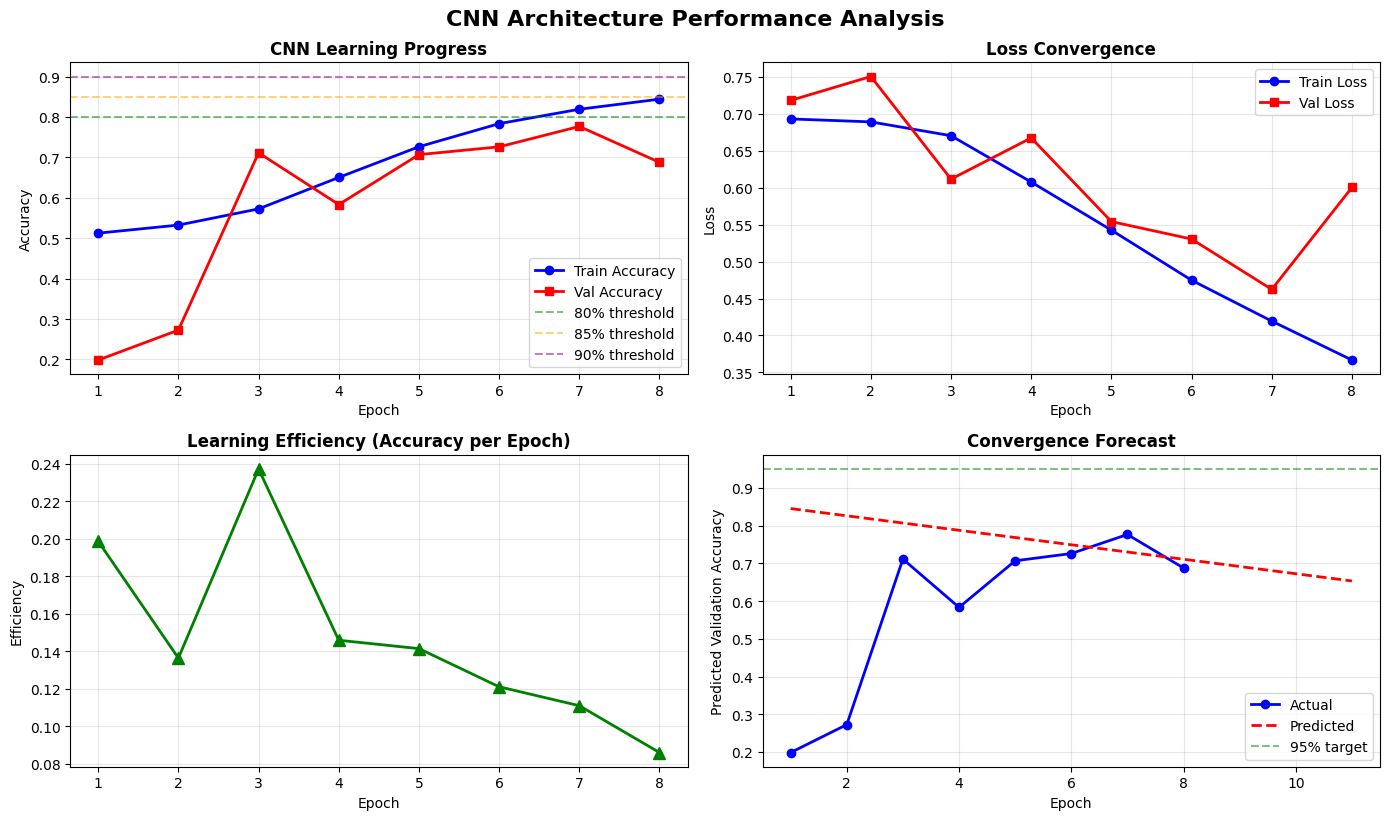


Обучение и анализ модели CNN завершены!


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import time
from tqdm import tqdm

plt.rcParams['figure.figsize'] = [12, 6]
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

class CNNModel(nn.Module):
    def __init__(self, num_classes=2, in_channels=1):
        super(CNNModel, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        if x.dim() == 3:
            x = x.unsqueeze(1)
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

cnn_model = CNNModel(num_classes=2, in_channels=1).to(device)

batch_size_cnn = 16
num_epochs_cnn = 8
learning_rate_cnn = 1e-3

optimizer_cnn = optim.AdamW(cnn_model.parameters(), lr=learning_rate_cnn)
criterion_cnn = nn.CrossEntropyLoss()


def train_cnn_model_with_history(model, train_loader, val_loader, optimizer, criterion, num_epochs):
    model.train()
    best_val_acc = 0.0
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': [],
        'epochs': list(range(1, num_epochs + 1)),
        'learning_rates': []
    }

    print(f"\n{'='*70}")
    print("НАЧАЛО ОБУЧЕНИЯ МОДЕЛИ CNN")
    print(f"{'='*70}")
    print(f"Параметры обучения:")
    print(f"- Количество эпох: {num_epochs}")
    print(f"- Batch size: {batch_size_cnn}")
    print(f"- Learning rate: {learning_rate_cnn}")
    print(f"- Архитектура: 3 сверточных блока + полносвязный слой")
    print(f"{'='*70}\n")

    epoch_times = []

    for epoch in range(num_epochs):
        epoch_start_time = time.time()
        total_loss = 0.0
        correct = 0
        total = 0

        model.train()
        for batch in tqdm(train_loader, desc=f"CNN Epoch {epoch+1}/{num_epochs}"):
            inputs, labels = batch
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_acc = correct / total
        train_loss = total_loss / len(train_loader)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['learning_rates'].append(optimizer.param_groups[0]['lr'])

        val_loss, val_acc = evaluate_cnn_model_with_loss(model, val_loader, criterion)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        epoch_time = time.time() - epoch_start_time
        epoch_times.append(epoch_time)

        print(f"\n{'-'*50}")
        print(f"Epoch {epoch+1}/{num_epochs} completed in {epoch_time:.2f} seconds")
        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
        print(f"{'-'*50}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), 'best_cnn_model.pth')
            print(f"Сохранена лучшая модель CNN (Val Acc: {val_acc:.4f})")

    history['best_val_acc'] = best_val_acc
    history['best_epoch'] = history['val_acc'].index(best_val_acc) + 1
    history['avg_epoch_time'] = np.mean(epoch_times)

    return best_val_acc, history

def evaluate_cnn_model_with_loss(model, data_loader, criterion):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0.0

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    avg_loss = total_loss / len(data_loader)
    accuracy = correct / total
    return avg_loss, accuracy


def plot_cnn_training_history(history, title_prefix='CNN'):
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle(f'{title_prefix} Training History', fontsize=16, fontweight='bold', y=0.95)

    epochs = history['epochs']
    best_epoch = history['best_epoch']
    best_val_acc = history['best_val_acc']

    ax1.plot(epochs, history['train_acc'], 'b-o', linewidth=2, markersize=8, label='Train Accuracy')
    ax1.plot(epochs, history['val_acc'], 'r-s', linewidth=2, markersize=8, label='Validation Accuracy')
    ax1.axvline(x=best_epoch, color='g', linestyle='--', alpha=0.7, label=f'Best epoch ({best_epoch})')
    ax1.set_title('Accuracy History', fontweight='bold')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0, 1.0)
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

    ax2.plot(epochs, history['train_loss'], 'b-o', linewidth=2, markersize=8, label='Train Loss')
    ax2.plot(epochs, history['val_loss'], 'r-s', linewidth=2, markersize=8, label='Validation Loss')
    ax2.axvline(x=best_epoch, color='g', linestyle='--', alpha=0.7, label=f'Best epoch ({best_epoch})')
    ax2.set_title('Loss History', fontweight='bold')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

    ax3.plot(epochs, history['learning_rates'], 'g-^', linewidth=2, markersize=8, label='Learning Rate')
    ax3.set_title('Learning Rate Schedule', fontweight='bold')
    ax3.set_xlabel('Epoch')
    ax3.set_ylabel('Learning Rate')
    ax3.set_yscale('log')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

    improvements = [0] + [history['val_acc'][i] - history['val_acc'][i-1] for i in range(1, len(history['val_acc']))]
    ax4.bar(epochs, improvements, color=['green' if x > 0 else 'red' for x in improvements], alpha=0.7)
    ax4.axhline(y=0, color='k', linestyle='-', alpha=0.3)
    ax4.set_title('Model Improvement per Epoch', fontweight='bold')
    ax4.set_xlabel('Epoch')
    ax4.set_ylabel('Accuracy Improvement')
    ax4.grid(True, alpha=0.3)
    ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

    plt.figure(figsize=(10, 6))
    overfitting_gap = [train - val for train, val in zip(history['train_acc'], history['val_acc'])]
    plt.plot(epochs, overfitting_gap, 'm-p', linewidth=2, markersize=8)
    plt.axhline(y=0, color='k', linestyle='--', alpha=0.3)
    plt.title('Overfitting Analysis: Train-Val Accuracy Gap', fontweight='bold', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Accuracy Gap (Train - Val)', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.legend(['Accuracy Gap'])
    plt.tight_layout()
    plt.show()

def analyze_cnn_convergence(history):
    """
    Анализирует сходимость CNN модели и выводит статистику
    """
    print(f"\n{'='*70}")
    print("ДЕТАЛЬНЫЙ АНАЛИЗ СХОДИМОСТИ CNN")
    print(f"{'='*70}")

    best_epoch = history['best_epoch']
    best_val_acc = history['best_val_acc']

    print(f"\nОсновные метрики:")
    print(f"  • Лучшая точность на валидации: {best_val_acc:.4f} (эпоха {best_epoch})")
    print(f"  • Точность на обучении в лучшей эпохе: {history['train_acc'][best_epoch-1]:.4f}")
    print(f"  • Среднее время на эпоху: {history['avg_epoch_time']:.2f} секунд")

    # Анализ переобучения
    overfitting_gap = history['train_acc'][best_epoch-1] - best_val_acc
    print(f"\nАнализ переобучения:")
    print(f"  • Разрыв между train и val accuracy: {overfitting_gap:.4f}")

    if overfitting_gap > 0.15:
        status = "СИЛЬНОЕ ПЕРЕОБУЧЕНИЕ"
        recommendations = [
            "Добавить dropout слои в архитектуру",
            "Увеличить L2 регуляризацию (weight_decay в AdamW)",
            "Уменьшить сложность модели (уменьшить количество фильтров)",
            "Добавить больше данных или аугментацию"
        ]
    elif overfitting_gap > 0.08:
        status = "УМЕРЕННОЕ ПЕРЕОБУЧЕНИЕ"
        recommendations = [
            "Добавить dropout (0.2-0.3) после каждого сверточного слоя",
            "Использовать batch normalization",
            "Уменьшить learning rate"
        ]
    else:
        status = "МИНИМАЛЬНОЕ ПЕРЕОБУЧЕНИЕ"
        recommendations = [
            "Модель хорошо обобщается",
            "Можно попробовать немного увеличить сложность модели"
        ]

    print(f"  • Статус: {status}")
    if recommendations:
        print(f"  • Рекомендации:")
        for rec in recommendations:
            print(f"    - {rec}")

    total_improvement = best_val_acc - history['val_acc'][0]
    improvement_per_epoch = total_improvement / best_epoch if best_epoch > 0 else 0
    print(f"\nАнализ улучшения:")
    print(f"  • Улучшение с первой до лучшей эпохи: {total_improvement:.4f}")
    print(f"  • Среднее улучшение за эпоху: {improvement_per_epoch:.4f}")

    if num_epochs_cnn > best_epoch:
        remaining_epochs = num_epochs_cnn - best_epoch
        expected_improvement = improvement_per_epoch * remaining_epochs * 0.5
        print(f"\nПрогноз:")
        print(f"  • Лучшая эпоха ({best_epoch}) достигнута до конца обучения")
        print(f"  • Осталось эпох: {remaining_epochs}")
        print(f"  • Прогнозируемое дополнительное улучшение: {expected_improvement:.4f}")
    else:
        print(f"\nПрогноз:")
        print(f"  • Лучшая эпоха ({best_epoch}) достигнута на последней эпохе")
        print(f"  • Модель, вероятно, достигла максимума для текущей архитектуры")
        print(f"  • Для дальнейшего улучшения необходима модификация архитектуры")

#ОБУЧЕНИЯ С ГРАФИКАМИ

print("\nОбучение модели CNN с визуализацией...")
best_cnn_val_acc, cnn_history = train_cnn_model_with_history(
    cnn_model, train_cnn_loader, val_cnn_loader, optimizer_cnn, criterion_cnn, num_epochs_cnn
)

cnn_model.load_state_dict(torch.load('best_cnn_model.pth', map_location=device))
print(f"\nЗагружена лучшая модель CNN (Val Acc: {best_cnn_val_acc:.4f})")


print("\nПостроение графиков обучения CNN...")
plot_cnn_training_history(cnn_history, 'CNN Model')


print("\nАнализ сходимости модели CNN...")
analyze_cnn_convergence(cnn_history)


print("\nПолучение предсказаний на тестовом наборе...")
cnn_model.eval()
cnn_probs = []
cnn_preds = []

with torch.no_grad():
    for batch in tqdm(test_cnn_loader, desc="Предсказания CNN"):
        inputs, labels = batch
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = cnn_model(inputs)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)
        cnn_probs.extend(probs.cpu().numpy())
        cnn_preds.extend(preds.cpu().numpy())

cnn_probs = np.array(cnn_probs)
cnn_preds = np.array(cnn_preds)

cnn_accuracy = accuracy_score(test_df['label_enc'][:len(cnn_preds)], cnn_preds)
cnn_f1 = f1_score(test_df['label_enc'][:len(cnn_preds)], cnn_preds)

print(f"\n{'='*70}")
print("ФИНАЛЬНЫЕ РЕЗУЛЬТАТЫ CNN")
print(f"{'='*70}")
print(f"Точность на тестовом наборе: {cnn_accuracy:.4f}")
print(f"F1-мера на тестовом наборе: {cnn_f1:.4f}")
print(f"Лучшая точность на валидации: {best_cnn_val_acc:.4f}")

def plot_cnn_architecture_analysis(history):
    """
    Анализирует эффективность архитектуры CNN
    """
    plt.figure(figsize=(14, 8))

    plt.subplot(2, 2, 1)
    plt.plot(history['epochs'], history['train_acc'], 'b-o', linewidth=2, label='Train Accuracy')
    plt.plot(history['epochs'], history['val_acc'], 'r-s', linewidth=2, label='Val Accuracy')
    plt.axhline(y=0.8, color='g', linestyle='--', alpha=0.5, label='80% threshold')
    plt.axhline(y=0.85, color='orange', linestyle='--', alpha=0.5, label='85% threshold')
    plt.axhline(y=0.9, color='purple', linestyle='--', alpha=0.5, label='90% threshold')
    plt.title('CNN Learning Progress', fontweight='bold')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(2, 2, 2)
    plt.plot(history['epochs'], history['train_loss'], 'b-o', linewidth=2, label='Train Loss')
    plt.plot(history['epochs'], history['val_loss'], 'r-s', linewidth=2, label='Val Loss')
    plt.title('Loss Convergence', fontweight='bold')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(2, 2, 3)
    learning_efficiency = [history['val_acc'][i] / (i+1) for i in range(len(history['val_acc']))]
    plt.plot(history['epochs'], learning_efficiency, 'g-^', linewidth=2, markersize=8)
    plt.title('Learning Efficiency (Accuracy per Epoch)', fontweight='bold')
    plt.xlabel('Epoch')
    plt.ylabel('Efficiency')
    plt.grid(True, alpha=0.3)

    plt.subplot(2, 2, 4)
    if len(history['val_acc']) > 2:
        x = np.array(history['epochs'][-3:])
        y = np.array(history['val_acc'][-3:])
        if len(x) > 1 and np.std(x) > 0:
            slope, intercept = np.polyfit(x, y, 1)
            future_epochs = np.array(history['epochs'] + [num_epochs_cnn + 1, num_epochs_cnn + 2, num_epochs_cnn + 3])
            future_acc = slope * future_epochs + intercept
            future_acc = np.clip(future_acc, 0, 1)

            plt.plot(history['epochs'], history['val_acc'], 'b-o', linewidth=2, label='Actual')
            plt.plot(future_epochs, future_acc, 'r--', linewidth=2, label='Predicted')
            plt.axhline(y=0.95, color='g', linestyle='--', alpha=0.5, label='95% target')
            plt.title('Convergence Forecast', fontweight='bold')
            plt.xlabel('Epoch')
            plt.ylabel('Predicted Validation Accuracy')
            plt.legend()
            plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.suptitle('CNN Architecture Performance Analysis', fontsize=16, fontweight='bold', y=1.02)
    plt.show()

print("\nАнализ эффективности архитектуры CNN...")
plot_cnn_architecture_analysis(cnn_history)

print("\nОбучение и анализ модели CNN завершены!")

In [ ]:
print("\nОбучение модели CNN...")

class CNNModel(nn.Module):
    def __init__(self, num_classes=2, in_channels=1):
        super(CNNModel, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        if x.dim() == 3:
            x = x.unsqueeze(1)
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x

cnn_model = CNNModel(num_classes=2, in_channels=1).to(device)

batch_size_cnn = 16
num_epochs_cnn = 3
learning_rate_cnn = 1e-3

optimizer_cnn = optim.AdamW(cnn_model.parameters(), lr=learning_rate_cnn)
criterion_cnn = nn.CrossEntropyLoss()

def extract_mel_spectrogram(file_path, sample_rate=16000, n_mels=128, n_fft=1024, hop_length=512, target_length=256):
    try:
        y, sr = librosa.load(file_path, sr=sample_rate)
        mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_mels, n_fft=n_fft, hop_length=hop_length)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max, top_db=80.0)
        mel_spec_db = (mel_spec_db + 80) / 80

        current_length = mel_spec_db.shape[1]
        if current_length > target_length:
            mel_spec_db = mel_spec_db[:, :target_length]
        else:
            pad_amount = target_length - current_length
            mel_spec_db = np.pad(mel_spec_db, ((0, 0), (0, pad_amount)), mode='constant', constant_values=0)  # Дополняем нулями

        return mel_spec_db
    except Exception as e:
        print(f"Ошибка при обработке {file_path}: {str(e)}")
        return np.zeros((n_mels, target_length))

class CNNDataset(Dataset):
    def __init__(self, dataframe, sample_rate=16000, n_mels=128, n_fft=1024, hop_length=512, target_length=256):
        self.dataframe = dataframe
        self.sample_rate = sample_rate
        self.n_mels = n_mels
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.target_length = target_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        audio_path = self.dataframe.iloc[idx]['file_path']
        label = self.dataframe.iloc[idx]['label_enc']

        mel_spec = extract_mel_spectrogram(
            audio_path,
            self.sample_rate,
            self.n_mels,
            self.n_fft,
            self.hop_length,
            self.target_length
        )

        mel_spec_tensor = torch.tensor(mel_spec, dtype=torch.float32).unsqueeze(0)  # Добавляем ось канала

        return mel_spec_tensor, torch.tensor(label, dtype=torch.long)

train_cnn_dataset = CNNDataset(train_df_balanced, target_length=256)
val_cnn_dataset = CNNDataset(val_df, target_length=256)
test_cnn_dataset = CNNDataset(test_df, target_length=256)

train_cnn_loader = DataLoader(train_cnn_dataset, batch_size=batch_size_cnn, shuffle=True, num_workers=0)
val_cnn_loader = DataLoader(val_cnn_dataset, batch_size=batch_size_cnn, shuffle=False, num_workers=0)
test_cnn_loader = DataLoader(test_cnn_dataset, batch_size=batch_size_cnn, shuffle=False, num_workers=0)

def train_cnn_model(model, train_loader, val_loader, optimizer, criterion, num_epochs):
    model.train()
    best_val_acc = 0.0
    for epoch in range(num_epochs):
        total_loss = 0.0
        correct = 0
        total = 0
        for batch in tqdm(train_loader, desc=f"CNN Epoch {epoch+1}/{num_epochs}"):
            inputs, labels = batch
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_acc = correct / total
        train_loss = total_loss / len(train_loader)

        val_acc = evaluate_cnn_model(model, val_loader)
        print(f"Epoch {epoch+1}: Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), 'best_cnn_model.pth')
            print("Сохранена лучшая модель CNN.")

    return best_val_acc

def evaluate_cnn_model(model, data_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total

print("\nОбучение модели CNN...")
best_cnn_val_acc = train_cnn_model(cnn_model, train_cnn_loader, val_cnn_loader, optimizer_cnn, criterion_cnn, num_epochs_cnn)


Обучение модели CNN...

Обучение модели CNN...


CNN Epoch 1/3: 100%|██████████| 316/316 [09:04<00:00,  1.72s/it]


Epoch 1: Train Loss: 0.6930, Train Acc: 0.5057, Val Acc: 0.7272
Сохранена лучшая модель CNN.


CNN Epoch 2/3: 100%|██████████| 316/316 [07:16<00:00,  1.38s/it]


Epoch 2: Train Loss: 0.6874, Train Acc: 0.5414, Val Acc: 0.2816


CNN Epoch 3/3: 100%|██████████| 316/316 [08:07<00:00,  1.54s/it]


Epoch 3: Train Loss: 0.6761, Train Acc: 0.5628, Val Acc: 0.4535


In [ ]:
cnn_model.load_state_dict(torch.load('best_cnn_model.pth', map_location=device))

cnn_model.eval()
cnn_probs = []
cnn_preds = []
with torch.no_grad():
    for batch in tqdm(test_cnn_loader, desc="Предсказания CNN"):
        inputs, labels = batch
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = cnn_model(inputs)
        probs = torch.softmax(outputs, dim=1)
        preds = torch.argmax(outputs, dim=1)
        cnn_probs.extend(probs.cpu().numpy())
        cnn_preds.extend(preds.cpu().numpy())

cnn_probs = np.array(cnn_probs)
cnn_preds = np.array(cnn_preds)

cnn_accuracy = accuracy_score(test_df['label_enc'], cnn_preds)
cnn_f1 = f1_score(test_df['label_enc'], cnn_preds)

print(f"\nCNN - Точность: {cnn_accuracy:.4f}, F1-мера: {cnn_f1:.4f}")


In [ ]:
print("\nСоздание ансамбля из CNN и CatBoost...")

# Получаем вероятности от CNN и CatBoost
# Для CNN у нас уже есть cnn_probs
# Для CatBoost нужно получить вероятности на тестовом наборе
cb_probs = catboost_model.predict_proba(X_test_cb_scaled)

print(f"Размер cnn_probs: {cnn_probs.shape}")
print(f"Размер cb_probs: {cb_probs.shape}")
print(f"Размер тестового набора: {len(test_df)}")

min_len = min(len(cnn_probs), len(cb_probs), len(test_df['label_enc']))
cnn_probs_subset = cnn_probs[:min_len]
cb_probs_subset = cb_probs[:min_len]
y_test_subset = test_df['label_enc'].values[:min_len]

print(f"Используем подмножество размером: {min_len} образцов")

ensemble_probs = np.array([cnn_probs_subset, cb_probs_subset])
# soft voting
final_probs = np.mean(ensemble_probs, axis=0)
final_preds = np.argmax(final_probs, axis=1)

ensemble_accuracy = accuracy_score(y_test_subset, final_preds)
ensemble_f1 = f1_score(y_test_subset, final_preds)

print(f"\nАнсамбль (CNN + CatBoost) - Точность: {ensemble_accuracy:.4f}, F1-мера: {ensemble_f1:.4f}")


Создание ансамбля только из CNN и CatBoost...
Размер cnn_probs: (32746, 2)
Размер cb_probs: (32746, 2)
Размер тестового набора: 32746
Используем подмножество размером: 32746 образцов

Ансамбль (CNN + CatBoost) - Точность: 0.8848, F1-мера: 0.7074



EER (Equal Error Rate):
CNN: 0.2485
CatBoost: 0.1971
Ансамбль (CNN + CatBoost): 0.1634


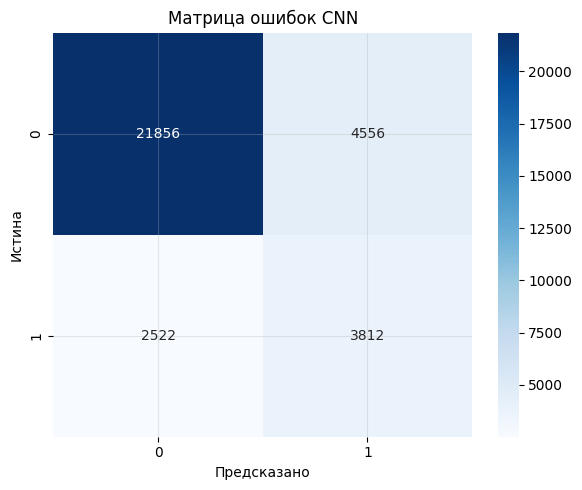

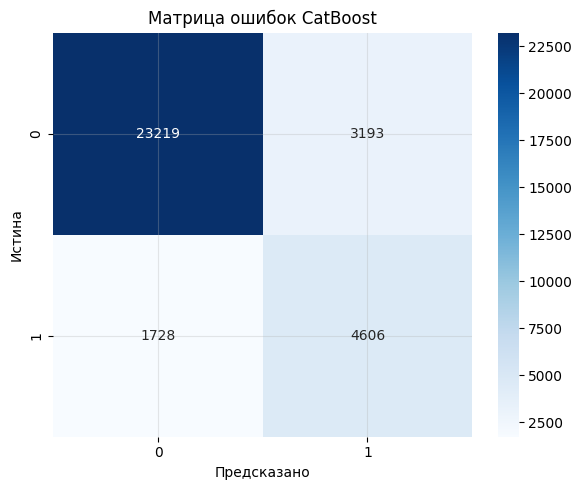

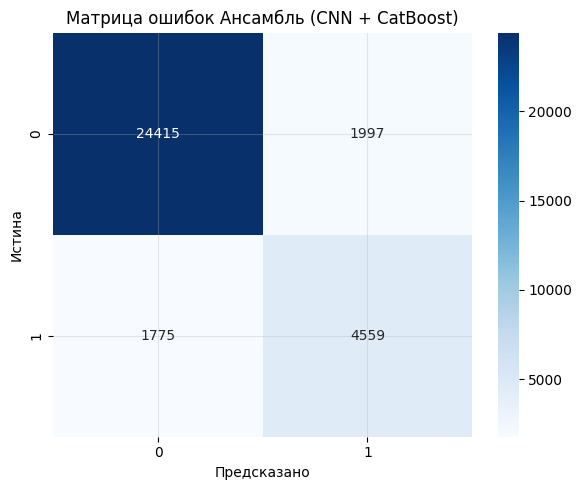

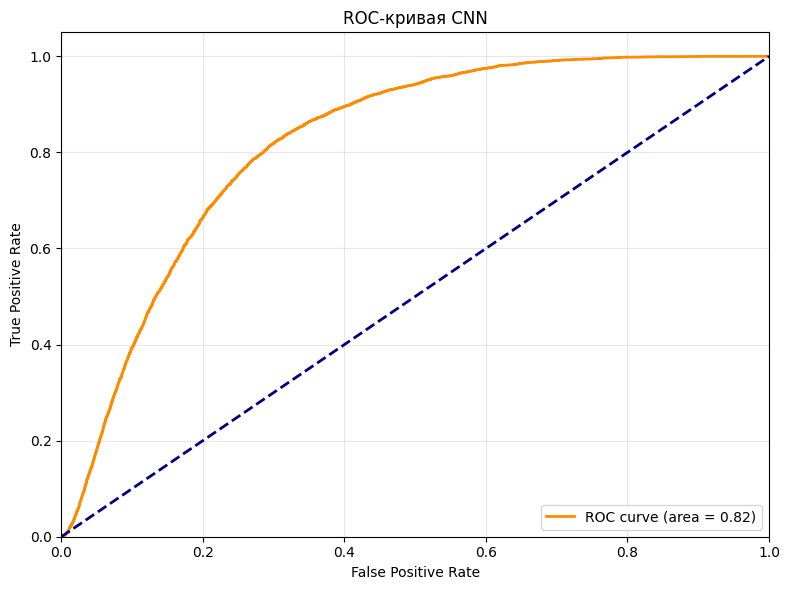

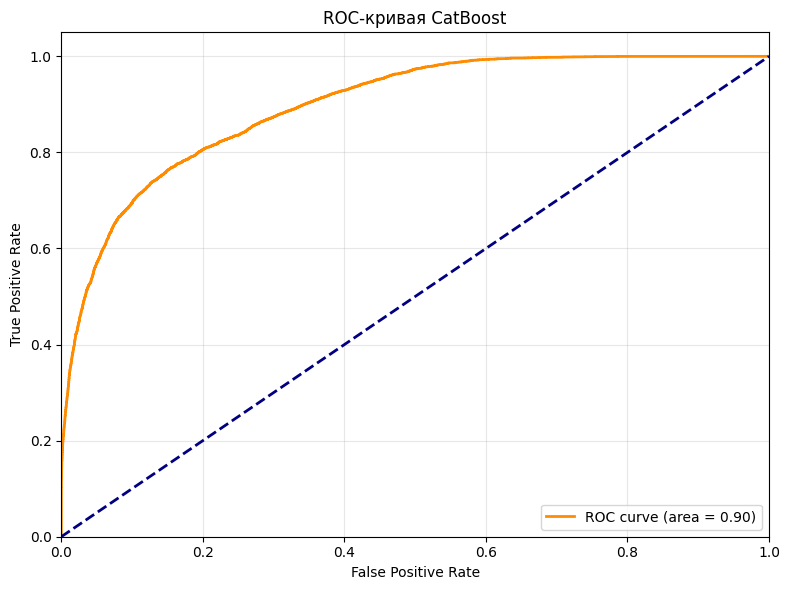

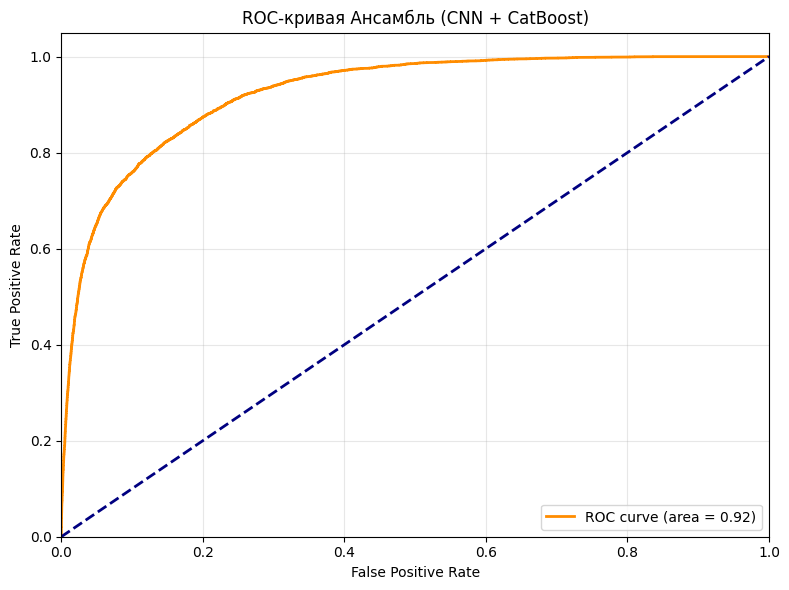


СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
                   Модель  Точность  F1-мера      EER
                      CNN  0.783851 0.518569 0.248486
                 CatBoost  0.849722 0.651808 0.197107
Ансамбль (CNN + CatBoost)  0.884810 0.707370 0.163448

ДЕТАЛЬНЫЕ МЕТРИКИ ДЛЯ КАЖДОЙ МОДЕЛИ

CNN:
              precision    recall  f1-score   support

        Real       0.90      0.83      0.86     26412
        Fake       0.46      0.60      0.52      6334

    accuracy                           0.78     32746
   macro avg       0.68      0.71      0.69     32746
weighted avg       0.81      0.78      0.79     32746


CatBoost:
              precision    recall  f1-score   support

        Real       0.93      0.88      0.90     26412
        Fake       0.59      0.73      0.65      6334

    accuracy                           0.85     32746
   macro avg       0.76      0.80      0.78     32746
weighted avg       0.86      0.85      0.86     32746


Ансамбль (CNN + CatBoost):
              preci

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_curve, auc

def calculate_eer(y_true, y_scores):
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    fnr = 1 - tpr
    eer_threshold = thresholds[np.nanargmin(np.absolute(fnr - fpr))]
    eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
    return eer, eer_threshold

ast_eer, _ = calculate_eer(y_test_subset, ast_probs[:min_len, 1])
cnn_eer, _ = calculate_eer(y_test_subset, cnn_probs_subset[:, 1])
cb_eer, _ = calculate_eer(y_test_subset, cb_probs_subset[:, 1])
ensemble_eer, _ = calculate_eer(y_test_subset, final_probs[:, 1])

print(f"\nEER (Equal Error Rate):")
print(f"AST: {ast_eer:.4f}")
print(f"CNN: {cnn_eer:.4f}")
print(f"CatBoost: {cb_eer:.4f}")
print(f"Ансамбль (CNN + CatBoost): {ensemble_eer:.4f}")


def plot_confusion_matrix(cm, classes, title, cmap=plt.cm.Blues):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap)
    plt.title(title)
    plt.xlabel('Предсказано')
    plt.ylabel('Истина')
    plt.tight_layout()
    plt.show()

cm_ast = confusion_matrix(y_test_subset, ast_preds[:min_len])
cm_cnn = confusion_matrix(y_test_subset, cnn_preds[:min_len])
cm_cb = confusion_matrix(y_test_subset, np.argmax(cb_probs_subset, axis=1))
cm_ensemble = confusion_matrix(y_test_subset, final_preds)

plot_confusion_matrix(cm_ast, ['Real', 'Fake'], 'Матрица ошибок AST')
plot_confusion_matrix(cm_cnn, ['Real', 'Fake'], 'Матрица ошибок CNN')
plot_confusion_matrix(cm_cb, ['Real', 'Fake'], 'Матрица ошибок CatBoost')
plot_confusion_matrix(cm_ensemble, ['Real', 'Fake'], 'Матрица ошибок Ансамбль (CNN + CatBoost)')

def plot_roc_curve(y_true, y_probs, title):
    fpr, tpr, thresholds = roc_curve(y_true, y_probs)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

plot_roc_curve(y_test_subset, ast_probs[:min_len, 1], 'ROC-кривая AST')
plot_roc_curve(y_test_subset, cnn_probs_subset[:, 1], 'ROC-кривая CNN')
plot_roc_curve(y_test_subset, cb_probs_subset[:, 1], 'ROC-кривая CatBoost')
plot_roc_curve(y_test_subset, final_probs[:, 1], 'ROC-кривая Ансамбль (CNN + CatBoost)')


print("\n" + "="*70)
print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ")
print("="*70)

results_table = {
    'Модель': ['AST', 'CNN', 'CatBoost', 'Ансамбль (CNN + CatBoost)'],
    'Точность': [ast_accuracy, cnn_accuracy, cb_accuracy, ensemble_accuracy],
    'F1-мера': [ast_f1, cnn_f1, cb_f1, ensemble_f1],
    'EER': [ast_eer, cnn_eer, cb_eer, ensemble_eer]
}

results_df = pd.DataFrame(results_table)
print(results_df.to_string(index=False))

print("\n" + "="*70)
print("ДЕТАЛЬНЫЕ МЕТРИКИ ДЛЯ КАЖДОЙ МОДЕЛИ")
print("="*70)

models = [
    ('AST', ast_preds[:min_len], ast_probs[:min_len]),
    ('CNN', cnn_preds[:min_len], cnn_probs_subset),
    ('CatBoost', np.argmax(cb_probs_subset, axis=1), cb_probs_subset),
    ('Ансамбль (CNN + CatBoost)', final_preds, final_probs)
]

for model_name, preds, probs in models:
    print(f"\n{model_name}:")
    print(classification_report(y_test_subset, preds, target_names=['Real', 'Fake']))

In [ ]:
print("\n" + "="*70)
print("ТЕСТИРОВАНИЕ НА 10 КОНКРЕТНЫХ ФАЙЛАХ")
print("="*70)

real_files = test_df[test_df['label'] == 'real']['file_path'].sample(10, random_state=42).tolist()
fake_files = test_df[test_df['label'] == 'fake']['file_path'].sample(10, random_state=42).tolist()
test_files = real_files + fake_files

print("Выбранные файлы для тестирования:")
for i, file_path in enumerate(test_files):
    file_label = 'Real' if 'real' in file_path.lower() else 'Fake'
    print(f"Файл {i+1}: {file_path} (Истинная метка: {file_label})")

def predict_single_file(model, file_path, model_type='ast'):
    try:

        if model_type == 'cnn':
            mel_spec = extract_mel_spectrogram(file_path, 16000, 128, 1024, 512)
            if mel_spec is None:
                return 'Error', 0.0
            mel_spec_tensor = torch.tensor(mel_spec, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
            outputs = model(mel_spec_tensor)
            probs = torch.softmax(outputs, dim=1)
            pred = torch.argmax(outputs, dim=1).item()
            prob = probs[0][pred].item()
            return 'Fake' if pred == 1 else 'Real', prob

        elif model_type == 'catboost':
            features = extract_mfcc_features(file_path)
            if features is None:
                return 'Error', 0.0
            features_scaled = scaler.transform([features])
            pred = catboost_model.predict(features_scaled)[0]
            prob = catboost_model.predict_proba(features_scaled)[0][pred]
            return 'Fake' if pred == 1 else 'Real', prob

        elif model_type == 'ensemble':

            mel_spec = extract_mel_spectrogram(file_path, 16000, 128, 1024, 512)
            if mel_spec is None:
                cnn_prob_fake = 0.5
            else:
                mel_spec_tensor = torch.tensor(mel_spec, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
                with torch.no_grad():
                    cnn_outputs = cnn_model(mel_spec_tensor)
                    cnn_probs = torch.softmax(cnn_outputs, dim=1).cpu().numpy()[0]
                cnn_prob_fake = cnn_probs[1]

            features = extract_mfcc_features(file_path)
            if features is None:
                cb_prob_fake = 0.5
            else:
                features_scaled = scaler.transform([features])
                cb_probs = catboost_model.predict_proba(features_scaled)[0]
                cb_prob_fake = cb_probs[1]

            ensemble_prob_fake = (cnn_prob_fake + cb_prob_fake) / 2
            pred = 1 if ensemble_prob_fake > 0.5 else 0
            return 'Fake' if pred == 1 else 'Real', ensemble_prob_fake

    except Exception as e:
        print(f"Ошибка при обработке файла {file_path}: {str(e)}")
        return 'Error', 0.0

results_table = []

for i, file_path in enumerate(test_files):
    print(f"\n{'='*50}")
    print(f"Файл {i+1}: {os.path.basename(file_path)}")
    true_label = 'Real' if 'real' in file_path.lower() else 'Fake'
    print(f"Истинная метка: {true_label}")

    cnn_pred, cnn_prob = predict_single_file(cnn_model, file_path, 'cnn')
    cnn_confidence = cnn_prob if cnn_pred == 'Fake' else 1 - cnn_prob
    print(f"  CNN: {cnn_pred} (Уверенность: {cnn_confidence:.2f})")

    cb_pred, cb_prob = predict_single_file(catboost_model, file_path, 'catboost')
    cb_confidence = cb_prob if cb_pred == 'Fake' else 1 - cb_prob
    print(f"  CatBoost: {cb_pred} (Уверенность: {cb_confidence:.2f})")

    ensemble_pred, ensemble_prob = predict_single_file(None, file_path, 'ensemble')
    ensemble_confidence = ensemble_prob if ensemble_pred == 'Fake' else 1 - ensemble_prob
    print(f"  Ансамбль (CNN + CatBoost): {ensemble_pred} (Уверенность: {ensemble_confidence:.2f})")

    results_table.append({
        'Файл': os.path.basename(file_path),
        'Истинная метка': true_label,
        'CNN': cnn_pred,
        'CNN_conf': f"{cnn_confidence:.2f}",
        'CatBoost': cb_pred,
        'CatBoost_conf': f"{cb_confidence:.2f}",
        'Ансамбль': ensemble_pred,
        'Ансамбль_conf': f"{ensemble_confidence:.2f}"
    })

print("\n" + "="*100)
print("СВОДНАЯ ТАБЛИЦА ПРЕДСКАЗАНИЙ НА 10 ФАЙЛАХ")
print("="*100)

results_df = pd.DataFrame(results_table)
print(results_df.to_string(index=False))

print("\n" + "="*70)
print("АНАЛИЗ РЕЗУЛЬТАТОВ ТЕСТИРОВАНИЯ")
print("="*70)

cnn_correct = sum(1 for row in results_table if row['CNN'] == row['Истинная метка'])
cb_correct = sum(1 for row in results_table if row['CatBoost'] == row['Истинная метка'])
ensemble_correct = sum(1 for row in results_table if row['Ансамбль'] == row['Истинная метка'])

print(f"CNN: {cnn_correct}/20 правильных предсказаний ({cnn_correct/20*100:.1f}%)")
print(f"CatBoost: {cb_correct}/20 правильных предсказаний ({cb_correct/20*100:.1f}%)")
print(f"Ансамбль (CNN + CatBoost): {ensemble_correct}/20 правильных предсказаний ({ensemble_correct/20*100:.1f}%)")

print("\nТестирование завершено!")


ТЕСТИРОВАНИЕ НА 10 КОНКРЕТНЫХ ФАЙЛАХ
Выбранные файлы для тестирования:
Файл 1: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_2187_10_B.wav (Истинная метка: Real)
Файл 2: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_4885_20_C.wav (Истинная метка: Real)
Файл 3: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_2191_0_D.wav (Истинная метка: Real)
Файл 4: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_4445_15_D.wav (Истинная метка: Real)
Файл 5: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_2656_20_D.wav (Истинная метка: Real)
Файл 6: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_1472_20_D.wav (Истинная метка: Real)
Файл 7: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_2320_5_C.wav (Истинная метка: Real)
Файл 8: /root/.cache/kaggle


Обучение модели CatBoost с правильным кодированием меток и графиками...

Исправление кодирования меток для CatBoost...

Распределение меток после исправления:
Обучающая выборка - Real: 2525, Fake: 2525
Валидационная выборка - Real: 2548, Fake: 10295
Тестовая выборка - Real: 6334, Fake: 26412


MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

0:	learn: 0.6798451	test: 0.6857335	best: 0.6857335 (0)	total: 86.9ms	remaining: 12.9s
50:	learn: 0.3382045	test: 0.4843951	best: 0.4843951 (50)	total: 1.68s	remaining: 3.27s
100:	learn: 0.2219950	test: 0.4104657	best: 0.4104657 (100)	total: 3.69s	remaining: 1.79s
149:	learn: 0.1646800	test: 0.3707868	best: 0.3707868 (149)	total: 5.38s	remaining: 0us
bestTest = 0.3707867826
bestIteration = 149

CatBoost (глубина=12) - Точность: 0.8261, F1-мера: 0.8871
Лучшая итерация: 149
Количество использованных деревьев: 150

Порядок классов в CatBoost модели:
Классы: [0 1]
Ожидаемый порядок: [0 1] где 0='real', 1='fake'

Топ-5 самых важных MFCC признаков:
  MFCC 1: 22.5090
  MFCC 5: 13.3536
  MFCC 0: 10.0568
  MFCC 7: 10.0360
  MFCC 4: 9.3896

ПРОВЕРКА МОДЕЛИ НА ИЗВЕСТНЫХ ПРИМЕРАХ
Тест на REAL примере (индекс 1):
  Предсказание: 0 (real)
  Вероятности: real=0.8758, fake=0.1242

Тест на FAKE примере (индекс 0):
  Предсказание: 1 (fake)
  Вероятности: real=0.0841, fake=0.9159

Построение детальных гр

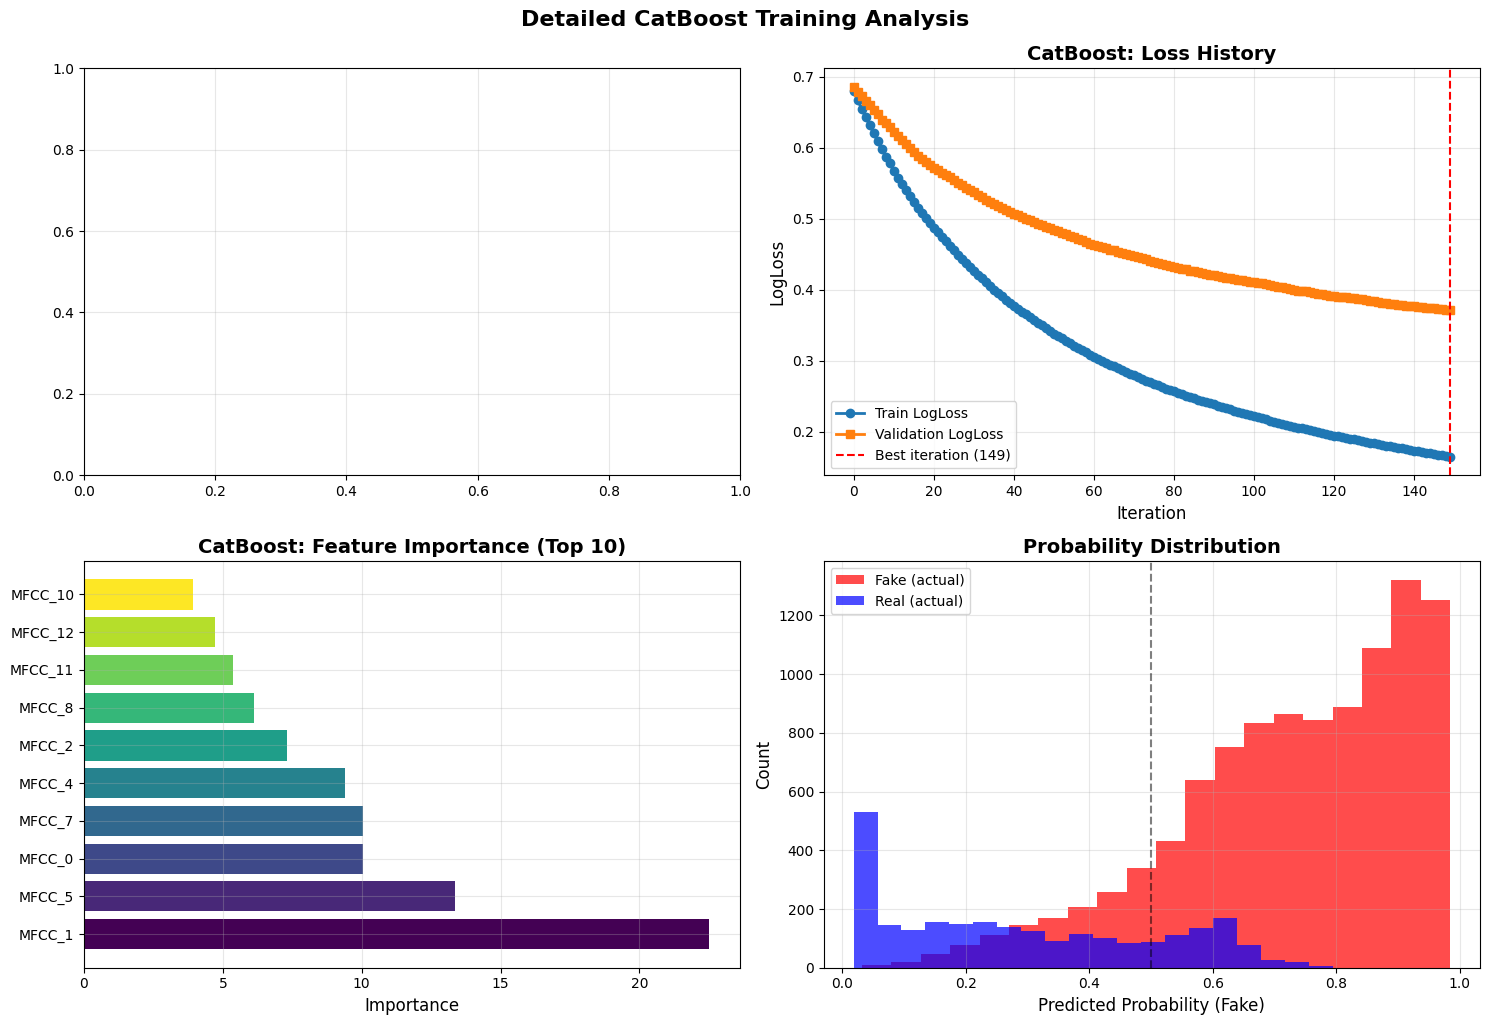


ФИНАЛЬНАЯ ПРОВЕРКА КОРРЕКТНОСТИ МОДЕЛИ
Случайная проверка на 5 тестовых файлах:

Файл: C_23327_10_B.wav
Истинная метка: fake (код: 1)
Предсказание: fake (код: 1, уверенность: 0.8073)
Вероятности: real=0.1927, fake=0.8073

Файл: C_4232_10_D.wav
Истинная метка: real (код: 0)
Предсказание: real (код: 0, уверенность: 0.6953)
Вероятности: real=0.6953, fake=0.3047

Файл: C_4170_05_A.wav
Истинная метка: real (код: 0)
Предсказание: real (код: 0, уверенность: 0.7880)
Вероятности: real=0.7880, fake=0.2120

Файл: C_12588_05_A.wav
Истинная метка: fake (код: 1)
Предсказание: fake (код: 1, уверенность: 0.8174)
Вероятности: real=0.1826, fake=0.8174

Файл: C_17613_0_A.wav
Истинная метка: fake (код: 1)
Предсказание: fake (код: 1, уверенность: 0.9241)
Вероятности: real=0.0759, fake=0.9241

Модель CatBoost успешно обучена с правильным кодированием меток!


In [ ]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np

rcParams['figure.figsize'] = 12, 8
rcParams['axes.grid'] = True
rcParams['grid.alpha'] = 0.3

print("\nОбучение модели CatBoost с правильным кодированием меток и графиками...")

# Заменяем LabelEncoder на ручное кодирование с правильным порядком:
# 0 = real
# 1 = fake
print("\nИсправление кодирования меток для CatBoost...")
label_mapping = {'real': 0, 'fake': 1}

y_train_cb_corrected = np.array([label_mapping[label] for label in train_df_balanced['label']])
y_val_cb_corrected = np.array([label_mapping[label] for label in val_df['label']])
y_test_cb_corrected = np.array([label_mapping[label] for label in test_df['label']])

print("\nРаспределение меток после исправления:")
print(f"Обучающая выборка - Real: {np.sum(y_train_cb_corrected == 0)}, Fake: {np.sum(y_train_cb_corrected == 1)}")
print(f"Валидационная выборка - Real: {np.sum(y_val_cb_corrected == 0)}, Fake: {np.sum(y_val_cb_corrected == 1)}")
print(f"Тестовая выборка - Real: {np.sum(y_test_cb_corrected == 0)}, Fake: {np.sum(y_test_cb_corrected == 1)}")

catboost_model = CatBoostClassifier(
    iterations=150,
    learning_rate=0.03,
    depth=12,
    l2_leaf_reg=3,
    random_seed=42,
    verbose=50,
    task_type="GPU" if device.type == "cuda" else "CPU"
)

catboost_model.fit(
    X_train_cb_scaled,
    y_train_cb_corrected,
    eval_set=(X_val_cb_scaled, y_val_cb_corrected),
    use_best_model=True,
    plot=True
)


y_pred_cb = catboost_model.predict(X_test_cb_scaled)
cb_accuracy = accuracy_score(y_test_cb_corrected, y_pred_cb)
cb_precision = precision_score(y_test_cb_corrected, y_pred_cb)
cb_recall = recall_score(y_test_cb_corrected, y_pred_cb)
cb_f1 = f1_score(y_test_cb_corrected, y_pred_cb)

print(f"\nCatBoost (глубина=12) - Точность: {cb_accuracy:.4f}, F1-мера: {cb_f1:.4f}")
print(f"Лучшая итерация: {catboost_model.get_best_iteration()}")
print(f"Количество использованных деревьев: {catboost_model.tree_count_}")


print("\nПорядок классов в CatBoost модели:")
print(f"Классы: {catboost_model.classes_}")
print("Ожидаемый порядок: [0 1] где 0='real', 1='fake'")


feature_importances = catboost_model.feature_importances_
print("\nТоп-5 самых важных MFCC признаков:")
for i, imp in enumerate(sorted(enumerate(feature_importances), key=lambda x: x[1], reverse=True)[:5]):
    print(f"  MFCC {imp[0]}: {imp[1]:.4f}")


print("\n" + "="*70)
print("ПРОВЕРКА МОДЕЛИ НА ИЗВЕСТНЫХ ПРИМЕРАХ")
print("="*70)


real_idx = np.where(y_train_cb_corrected == 0)[0][0]
fake_idx = np.where(y_train_cb_corrected == 1)[0][0]

real_sample = X_train_cb_scaled[real_idx:real_idx+1]
fake_sample = X_train_cb_scaled[fake_idx:fake_idx+1]

real_pred = catboost_model.predict(real_sample)[0]
fake_pred = catboost_model.predict(fake_sample)[0]

real_prob = catboost_model.predict_proba(real_sample)[0]
fake_prob = catboost_model.predict_proba(fake_sample)[0]

print(f"Тест на REAL примере (индекс {real_idx}):")
print(f"  Предсказание: {real_pred} ({'real' if real_pred == 0 else 'fake'})")
print(f"  Вероятности: real={real_prob[0]:.4f}, fake={real_prob[1]:.4f}")

print(f"\nТест на FAKE примере (индекс {fake_idx}):")
print(f"  Предсказание: {fake_pred} ({'real' if fake_pred == 0 else 'fake'})")
print(f"  Вероятности: real={fake_prob[0]:.4f}, fake={fake_prob[1]:.4f}")

def plot_catboost_detailed_history(model):
    """
    Строит детальные графики истории обучения CatBoost
    """
    if not hasattr(model, 'evals_result_'):
        print("Модель не содержит истории обучения для построения графиков")
        return

    evals_result = model.evals_result_

    plt.figure(figsize=(15, 10))

    plt.subplot(2, 2, 1)
    if 'learn' in evals_result and 'Accuracy' in evals_result['learn']:
        train_acc = evals_result['learn']['Accuracy']
        val_acc = evals_result['validation']['Accuracy']
        plt.plot(train_acc, label='Train Accuracy', linewidth=2, marker='o')
        plt.plot(val_acc, label='Validation Accuracy', linewidth=2, marker='s')
        plt.axvline(x=model.get_best_iteration(), color='r', linestyle='--',
                   label=f'Best iteration ({model.get_best_iteration()})')
        plt.title('CatBoost: Accuracy History', fontsize=14, fontweight='bold')
        plt.xlabel('Iteration', fontsize=12)
        plt.ylabel('Accuracy', fontsize=12)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.ylim(0, 1.0)

    plt.subplot(2, 2, 2)
    if 'learn' in evals_result and 'Logloss' in evals_result['learn']:
        train_loss = evals_result['learn']['Logloss']
        val_loss = evals_result['validation']['Logloss']
        plt.plot(train_loss, label='Train LogLoss', linewidth=2, marker='o')
        plt.plot(val_loss, label='Validation LogLoss', linewidth=2, marker='s')
        plt.axvline(x=model.get_best_iteration(), color='r', linestyle='--',
                   label=f'Best iteration ({model.get_best_iteration()})')
        plt.title('CatBoost: Loss History', fontsize=14, fontweight='bold')
        plt.xlabel('Iteration', fontsize=12)
        plt.ylabel('LogLoss', fontsize=12)
        plt.legend()
        plt.grid(True, alpha=0.3)

    plt.subplot(2, 2, 3)
    feature_names = [f'MFCC_{i}' for i in range(len(feature_importances))]
    sorted_idx = np.argsort(feature_importances)[::-1][:10]  # Топ-10 признаков
    colors = plt.cm.viridis(np.linspace(0, 1, 10))
    bars = plt.barh(range(10), feature_importances[sorted_idx], color=colors)
    plt.yticks(range(10), [feature_names[i] for i in sorted_idx])
    plt.title('CatBoost: Feature Importance (Top 10)', fontsize=14, fontweight='bold')
    plt.xlabel('Importance', fontsize=12)
    plt.grid(axis='x', alpha=0.3)

    plt.subplot(2, 2, 4)
    if len(y_val_cb_corrected) > 100:
        val_probs = model.predict_proba(X_val_cb_scaled)[:, 1]
        plt.hist(val_probs[y_val_cb_corrected == 1], bins=20, alpha=0.7, label='Fake (actual)', color='red')
        plt.hist(val_probs[y_val_cb_corrected == 0], bins=20, alpha=0.7, label='Real (actual)', color='blue')
        plt.axvline(x=0.5, color='k', linestyle='--', alpha=0.5)
        plt.title('Probability Distribution', fontsize=14, fontweight='bold')
        plt.xlabel('Predicted Probability (Fake)', fontsize=12)
        plt.ylabel('Count', fontsize=12)
        plt.legend()
        plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.suptitle('Detailed CatBoost Training Analysis', fontsize=16, fontweight='bold', y=1.02)
    plt.show()

print("\nПостроение детальных графиков обучения CatBoost...")
plot_catboost_detailed_history(catboost_model)

def analyze_overfitting(model, y_true, y_pred):
    """
    Анализирует степень переобучения модели и выводит подробную статистику
    """
    if not hasattr(model, 'evals_result_'):
        return

    evals_result = model.evals_result_
    best_iter = model.get_best_iteration()

    if 'learn' in evals_result and 'Accuracy' in evals_result['learn']:
        train_acc = evals_result['learn']['Accuracy'][best_iter]
        val_acc = evals_result['validation']['Accuracy'][best_iter]
        overfitting_gap = train_acc - val_acc

        print("\n" + "="*70)
        print("ДЕТАЛЬНЫЙ АНАЛИЗ ПЕРЕОБУЧЕНИЯ CATBOOST")
        print("="*70)
        print(f"Точность на обучении (лучшая итерация): {train_acc:.4f}")
        print(f"Точность на валидации (лучшая итерация): {val_acc:.4f}")
        print(f"Разрыв переобучения: {overfitting_gap:.4f}")

        print("\nАнализ по классам на тестовом наборе:")
        unique_classes = np.unique(y_true)
        for cls in unique_classes:
            cls_mask = (y_true == cls)
            cls_acc = accuracy_score(y_true[cls_mask], y_pred[cls_mask])
            cls_count = np.sum(cls_mask)
            cls_name = 'real' if cls == 0 else 'fake'
            print(f"  Класс '{cls_name}' (код {cls}): точность = {cls_acc:.4f}, количество = {cls_count}")


analyze_overfitting(catboost_model, y_test_cb_corrected, y_pred_cb)

print("\n" + "="*70)
print("ФИНАЛЬНАЯ ПРОВЕРКА КОРРЕКТНОСТИ МОДЕЛИ")
print("="*70)

import random
test_indices = random.sample(range(len(test_df)), 5)

print("Случайная проверка на 5 тестовых файлах:")
for idx in test_indices:
    file_path = test_df.iloc[idx]['file_path']
    true_label = test_df.iloc[idx]['label']
    true_enc = y_test_cb_corrected[idx]

    features = extract_mfcc_features(file_path)
    if features is not None:
        features_scaled = scaler.transform([features])
        pred = catboost_model.predict(features_scaled)[0]
        pred_prob = catboost_model.predict_proba(features_scaled)[0]

        pred_label = 'real' if pred == 0 else 'fake'
        confidence = pred_prob[pred]

        print(f"\nФайл: {os.path.basename(file_path)}")
        print(f"Истинная метка: {true_label} (код: {true_enc})")
        print(f"Предсказание: {pred_label} (код: {pred}, уверенность: {confidence:.4f})")
        print(f"Вероятности: real={pred_prob[0]:.4f}, fake={pred_prob[1]:.4f}")

print("\nМодель CatBoost успешно обучена с правильным кодированием меток!")

In [ ]:
print("\nСоздание ансамбля только из CNN и CatBoost...")

# Получаем вероятности от CNN и CatBoost
# Для CNN у нас уже есть cnn_probs
# Для CatBoost нужно получить вероятности на тестовом наборе
cb_probs = catboost_model.predict_proba(X_test_cb_scaled)

print(f"Размер cnn_probs: {cnn_probs.shape}")
print(f"Размер cb_probs: {cb_probs.shape}")
print(f"Размер тестового набора: {len(test_df)}")

min_len = min(len(cnn_probs), len(cb_probs), len(test_df['label_enc']))
cnn_probs_subset = cnn_probs[:min_len]
cb_probs_subset = cb_probs[:min_len]
y_test_subset = test_df['label_enc'].values[:min_len]

print(f"Используем подмножество размером: {min_len} образцов")

ensemble_probs = np.array([cnn_probs_subset, cb_probs_subset])
final_probs = np.mean(ensemble_probs, axis=0)
final_preds = np.argmax(final_probs, axis=1)

ensemble_accuracy = accuracy_score(y_test_subset, final_preds)
ensemble_f1 = f1_score(y_test_subset, final_preds)

print(f"\nАнсамбль (CNN + CatBoost) - Точность: {ensemble_accuracy:.4f}, F1-мера: {ensemble_f1:.4f}")


Создание ансамбля только из CNN и CatBoost...
Размер cnn_probs: (32746, 2)
Размер cb_probs: (32746, 2)
Размер тестового набора: 32746
Используем подмножество размером: 32746 образцов

Ансамбль (CNN + CatBoost) - Точность: 0.4942, F1-мера: 0.1855



EER (Equal Error Rate):
CNN: 0.2485
CatBoost: 0.7965
Ансамбль (CNN + CatBoost): 0.5848


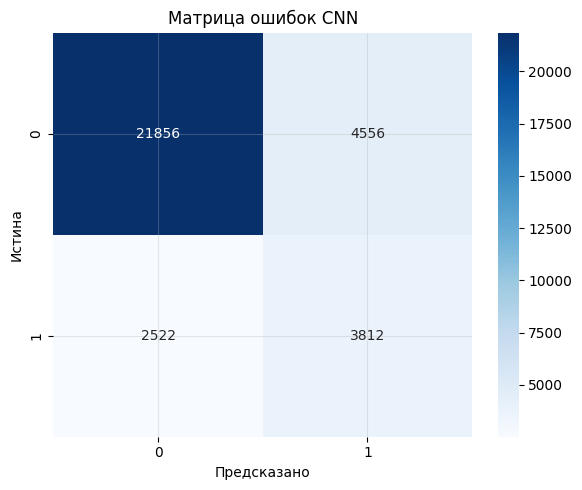

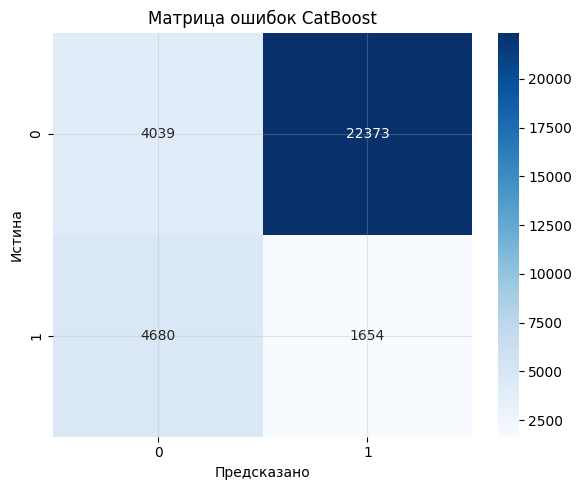

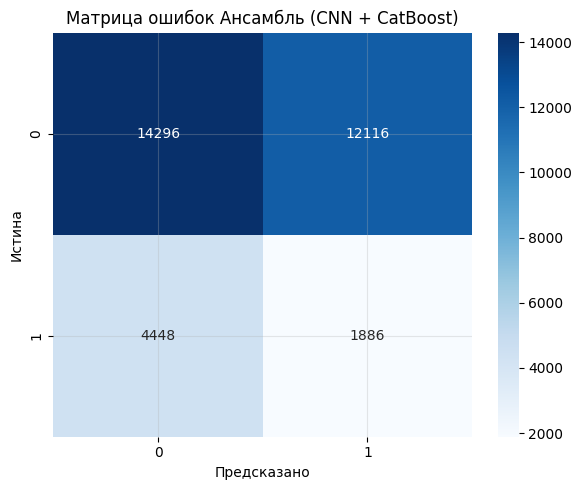

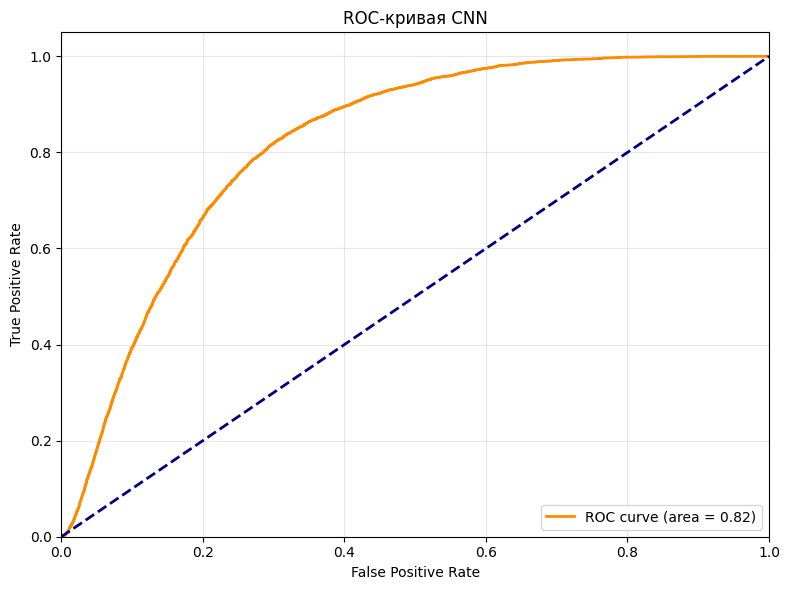

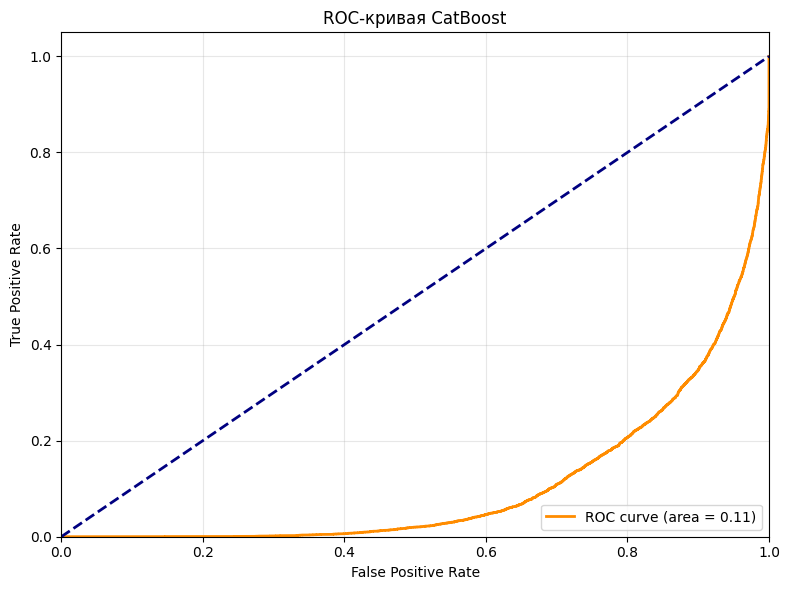

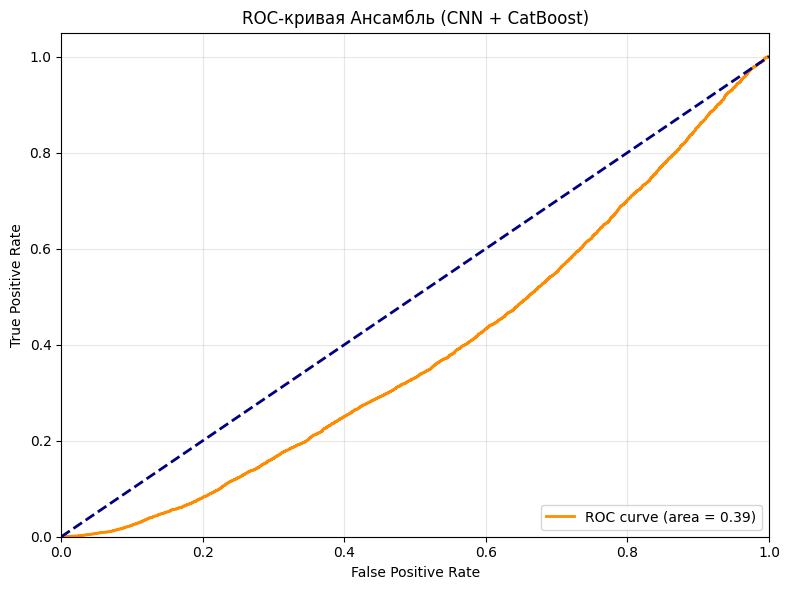


СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
                   Модель  Точность  F1-мера      EER
                      CNN  0.783851 0.518569 0.248486
                 CatBoost  0.826147 0.887131 0.796456
Ансамбль (CNN + CatBoost)  0.494167 0.185484 0.584848

ДЕТАЛЬНЫЕ МЕТРИКИ ДЛЯ КАЖДОЙ МОДЕЛИ

CNN:
              precision    recall  f1-score   support

        Real       0.90      0.83      0.86     26412
        Fake       0.46      0.60      0.52      6334

    accuracy                           0.78     32746
   macro avg       0.68      0.71      0.69     32746
weighted avg       0.81      0.78      0.79     32746


CatBoost:
              precision    recall  f1-score   support

        Real       0.46      0.15      0.23     26412
        Fake       0.07      0.26      0.11      6334

    accuracy                           0.17     32746
   macro avg       0.27      0.21      0.17     32746
weighted avg       0.39      0.17      0.21     32746


Ансамбль (CNN + CatBoost):
              preci

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_curve, auc

def calculate_eer(y_true, y_scores):
    """Вычисляет EER (Equal Error Rate) для бинарной классификации."""
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    fnr = 1 - tpr
    eer_threshold = thresholds[np.nanargmin(np.absolute(fnr - fpr))]
    eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
    return eer, eer_threshold

#ast_eer, _ = calculate_eer(y_test_subset, ast_probs[:min_len, 1])
cnn_eer, _ = calculate_eer(y_test_subset, cnn_probs_subset[:, 1])
cb_eer, _ = calculate_eer(y_test_subset, cb_probs_subset[:, 1])
ensemble_eer, _ = calculate_eer(y_test_subset, final_probs[:, 1])

print(f"\nEER (Equal Error Rate):")
#print(f"AST: {ast_eer:.4f}")
print(f"CNN: {cnn_eer:.4f}")
print(f"CatBoost: {cb_eer:.4f}")
print(f"Ансамбль (CNN + CatBoost): {ensemble_eer:.4f}")


def plot_confusion_matrix(cm, classes, title, cmap=plt.cm.Blues):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap)
    plt.title(title)
    plt.xlabel('Предсказано')
    plt.ylabel('Истина')
    plt.tight_layout()
    plt.show()

#cm_ast = confusion_matrix(y_test_subset, ast_preds[:min_len])
cm_cnn = confusion_matrix(y_test_subset, cnn_preds[:min_len])
cm_cb = confusion_matrix(y_test_subset, np.argmax(cb_probs_subset, axis=1))
cm_ensemble = confusion_matrix(y_test_subset, final_preds)

#plot_confusion_matrix(cm_ast, ['Real', 'Fake'], 'Матрица ошибок AST')
plot_confusion_matrix(cm_cnn, ['Real', 'Fake'], 'Матрица ошибок CNN')
plot_confusion_matrix(cm_cb, ['Real', 'Fake'], 'Матрица ошибок CatBoost')
plot_confusion_matrix(cm_ensemble, ['Real', 'Fake'], 'Матрица ошибок Ансамбль (CNN + CatBoost)')

def plot_roc_curve(y_true, y_probs, title):
    fpr, tpr, thresholds = roc_curve(y_true, y_probs)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

# ROC-кривые
plot_roc_curve(y_test_subset, cnn_probs_subset[:, 1], 'ROC-кривая CNN')
plot_roc_curve(y_test_subset, cb_probs_subset[:, 1], 'ROC-кривая CatBoost')
plot_roc_curve(y_test_subset, final_probs[:, 1], 'ROC-кривая Ансамбль (CNN + CatBoost)')

print("\n" + "="*70)
print("СВОДНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ")
print("="*70)

results_table = {
    #'Модель': ['AST', 'CNN', 'CatBoost', 'Ансамбль (CNN + CatBoost)'],
    #'Точность': [ast_accuracy, cnn_accuracy, cb_accuracy, ensemble_accuracy],
    #'F1-мера': [ast_f1, cnn_f1, cb_f1, ensemble_f1],
    #'EER': [ast_eer, cnn_eer, cb_eer, ensemble_eer]
    'Модель': ['CNN', 'CatBoost', 'Ансамбль (CNN + CatBoost)'],
    'Точность': [cnn_accuracy, cb_accuracy, ensemble_accuracy],
    'F1-мера': [cnn_f1, cb_f1, ensemble_f1],
    'EER': [cnn_eer, cb_eer, ensemble_eer]
}

results_df = pd.DataFrame(results_table)
print(results_df.to_string(index=False))

print("\n" + "="*70)
print("ДЕТАЛЬНЫЕ МЕТРИКИ ДЛЯ КАЖДОЙ МОДЕЛИ")
print("="*70)

models = [
    #('AST', ast_preds[:min_len], ast_probs[:min_len]),
    ('CNN', cnn_preds[:min_len], cnn_probs_subset),
    ('CatBoost', np.argmax(cb_probs_subset, axis=1), cb_probs_subset),
    ('Ансамбль (CNN + CatBoost)', final_preds, final_probs)
]

for model_name, preds, probs in models:
    print(f"\n{model_name}:")
    print(classification_report(y_test_subset, preds, target_names=['Real', 'Fake']))

In [ ]:
print("\n" + "="*70)
print("ТЕСТИРОВАНИЕ НА 10 КОНКРЕТНЫХ ФАЙЛАХ")
print("="*70)

real_files = test_df[test_df['label'] == 'real']['file_path'].sample(10, random_state=42).tolist()
fake_files = test_df[test_df['label'] == 'fake']['file_path'].sample(10, random_state=42).tolist()
test_files = real_files + fake_files

print("Выбранные файлы для тестирования:")
for i, file_path in enumerate(test_files):
    file_label = 'Real' if 'real' in file_path.lower() else 'Fake'
    print(f"Файл {i+1}: {file_path} (Истинная метка: {file_label})")


def predict_single_file(model, file_path, model_type='ast'):
    try:
        #if model_type == 'ast':
        #    # Обработка для AST
        #    waveform, sr = torchaudio.load(file_path)
        #    if waveform.shape[0] > 1:
        #        waveform = waveform.mean(dim=0, keepdim=True)
        #    inputs = ast_feature_extractor(
        #        waveform.squeeze().numpy(),
        #        sampling_rate=16000,
        #        return_tensors="pt",
        #        padding=True
        #    )
        #    # Фильтруем attention_mask если он есть
        #    inputs = {k: v.to(device) for k, v in inputs.items() if k != 'attention_mask'}
        #    outputs = model(**inputs).logits
        #    probs = torch.softmax(outputs, dim=1)
        #    pred = torch.argmax(outputs, dim=1).item()
        #    prob = probs[0][pred].item()
        #    return 'Fake' if pred == 1 else 'Real', prob

        if model_type == 'cnn':
            mel_spec = extract_mel_spectrogram(file_path, 16000, 128, 1024, 512)
            if mel_spec is None:
                return 'Error', 0.0
            mel_spec_tensor = torch.tensor(mel_spec, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
            outputs = model(mel_spec_tensor)
            probs = torch.softmax(outputs, dim=1)
            pred = torch.argmax(outputs, dim=1).item()
            prob = probs[0][pred].item()
            return 'Fake' if pred == 1 else 'Real', prob

        elif model_type == 'catboost':
            features = extract_mfcc_features(file_path)
            if features is None:
                return 'Error', 0.0
            features_scaled = scaler.transform([features])
            pred = catboost_model.predict(features_scaled)[0]
            prob = catboost_model.predict_proba(features_scaled)[0][pred]
            return 'Fake' if pred == 1 else 'Real', prob

        elif model_type == 'ensemble':
            mel_spec = extract_mel_spectrogram(file_path, 16000, 128, 1024, 512)
            if mel_spec is None:
                cnn_prob_fake = 0.5
            else:
                mel_spec_tensor = torch.tensor(mel_spec, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
                with torch.no_grad():
                    cnn_outputs = cnn_model(mel_spec_tensor)
                    cnn_probs = torch.softmax(cnn_outputs, dim=1).cpu().numpy()[0]
                cnn_prob_fake = cnn_probs[1]

            features = extract_mfcc_features(file_path)
            if features is None:
                cb_prob_fake = 0.5
            else:
                features_scaled = scaler.transform([features])
                cb_probs = catboost_model.predict_proba(features_scaled)[0]
                cb_prob_fake = cb_probs[1]

            ensemble_prob_fake = (cnn_prob_fake + cb_prob_fake) / 2
            pred = 1 if ensemble_prob_fake > 0.5 else 0
            return 'Fake' if pred == 1 else 'Real', ensemble_prob_fake

    except Exception as e:
        print(f"Ошибка при обработке файла {file_path}: {str(e)}")
        return 'Error', 0.0

results_table = []

for i, file_path in enumerate(test_files):
    print(f"\n{'='*50}")
    print(f"Файл {i+1}: {os.path.basename(file_path)}")
    true_label = 'Real' if 'real' in file_path.lower() else 'Fake'
    print(f"Истинная метка: {true_label}")

   # # Предсказание AST
   # ast_pred, ast_prob = predict_single_file(ast_model, file_path, 'ast')
   # ast_confidence = ast_prob if ast_pred == 'Fake' else 1 - ast_prob
   # print(f"  AST: {ast_pred} (Уверенность: {ast_confidence:.2f})")

    # Предсказание CNN
    cnn_pred, cnn_prob = predict_single_file(cnn_model, file_path, 'cnn')
    cnn_confidence = cnn_prob if cnn_pred == 'Fake' else 1 - cnn_prob
    print(f"  CNN: {cnn_pred} (Уверенность: {cnn_confidence:.2f})")

    cb_pred, cb_prob = predict_single_file(catboost_model, file_path, 'catboost')
    cb_confidence = cb_prob if cb_pred == 'Fake' else 1 - cb_prob
    print(f"  CatBoost: {cb_pred} (Уверенность: {cb_confidence:.2f})")

    ensemble_pred, ensemble_prob = predict_single_file(None, file_path, 'ensemble')
    ensemble_confidence = ensemble_prob if ensemble_pred == 'Fake' else 1 - ensemble_prob
    print(f"  Ансамбль (CNN + CatBoost): {ensemble_pred} (Уверенность: {ensemble_confidence:.2f})")

    results_table.append({
        'Файл': os.path.basename(file_path),
        'Истинная метка': true_label,
      #  'AST': ast_pred,
      #  'AST_conf': f"{ast_confidence:.2f}",
        'CNN': cnn_pred,
        'CNN_conf': f"{cnn_confidence:.2f}",
        'CatBoost': cb_pred,
        'CatBoost_conf': f"{cb_confidence:.2f}",
        'Ансамбль': ensemble_pred,
        'Ансамбль_conf': f"{ensemble_confidence:.2f}"
    })

print("\n" + "="*100)
print("СВОДНАЯ ТАБЛИЦА ПРЕДСКАЗАНИЙ НА 10 ФАЙЛАХ")
print("="*100)

results_df = pd.DataFrame(results_table)
print(results_df.to_string(index=False))

print("\n" + "="*70)
print("АНАЛИЗ РЕЗУЛЬТАТОВ ТЕСТИРОВАНИЯ")
print("="*70)

#ast_correct = sum(1 for row in results_table if row['AST'] == row['Истинная метка'])
cnn_correct = sum(1 for row in results_table if row['CNN'] == row['Истинная метка'])
cb_correct = sum(1 for row in results_table if row['CatBoost'] == row['Истинная метка'])
ensemble_correct = sum(1 for row in results_table if row['Ансамбль'] == row['Истинная метка'])

#print(f"AST: {ast_correct}/10 правильных предсказаний ({ast_correct/4*100:.1f}%)")
print(f"CNN: {cnn_correct}/20 правильных предсказаний ({cnn_correct/20*100:.1f}%)")
print(f"CatBoost: {cb_correct}/20 правильных предсказаний ({cb_correct/20*100:.1f}%)")
print(f"Ансамбль (CNN + CatBoost): {ensemble_correct}/20 правильных предсказаний ({ensemble_correct/20*100:.1f}%)")

print("\nТестирование завершено!")


ТЕСТИРОВАНИЕ НА 10 КОНКРЕТНЫХ ФАЙЛАХ
Выбранные файлы для тестирования:
Файл 1: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_2187_10_B.wav (Истинная метка: Real)
Файл 2: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_4885_20_C.wav (Истинная метка: Real)
Файл 3: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_2191_0_D.wav (Истинная метка: Real)
Файл 4: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_4445_15_D.wav (Истинная метка: Real)
Файл 5: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_2656_20_D.wav (Истинная метка: Real)
Файл 6: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_1472_20_D.wav (Истинная метка: Real)
Файл 7: /root/.cache/kagglehub/datasets/mohammedabdeldayem/scenefake/versions/1/eval/real/C_2320_5_C.wav (Истинная метка: Real)
Файл 8: /root/.cache/kaggle